In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [7]:
# Load Cleaned Datasets

data_path = "data/processed/"

nav = pd.read_csv(data_path + "nav_history_cleaned.csv")
aum = pd.read_csv(data_path + "aum_by_fund_house_cleaned.csv")
sip = pd.read_csv(data_path + "monthly_sip_inflows_cleaned.csv")
category = pd.read_csv(data_path + "category_inflows_cleaned.csv")
fund = pd.read_csv(data_path + "fund_master_cleaned.csv")
folio = pd.read_csv(data_path + "industry_folio_count_cleaned.csv")
transactions = pd.read_csv(data_path + "investor_transactions_cleaned.csv")
holdings = pd.read_csv(data_path + "portfolio_holdings_cleaned.csv")
benchmark = pd.read_csv(data_path + "benchmark_indices_cleaned.csv")
performance = pd.read_csv(data_path + "scheme_performance_cleaned.csv")

print("All CSV Files Loaded Successfully!")

All CSV Files Loaded Successfully!


In [13]:
datasets = {
    "NAV": nav,
    "AUM": aum,
    "SIP": sip,
    "Category": category,
    "Fund Master": fund,
    "Folio": folio,
    "Transactions": transactions,
    "Holdings": holdings,
    "Benchmark": benchmark,
    "Performance": performance
}

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))


Dataset: NAV
Shape: (46000, 3)
Columns: ['amfi_code', 'date', 'nav']

Dataset: AUM
Shape: (90, 5)
Columns: ['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']

Dataset: SIP
Shape: (48, 6)
Columns: ['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']

Dataset: Category
Shape: (144, 3)
Columns: ['month', 'category', 'net_inflow_crore']

Dataset: Fund Master
Shape: (40, 15)
Columns: ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

Dataset: Folio
Shape: (21, 6)
Columns: ['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']

Dataset: Transactions
Shape: (13062, 13)
Columns: ['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amoun

In [9]:
datasets = {
    "NAV": nav,
    "AUM": aum,
    "SIP": sip,
    "Category": category,
    "Fund Master": fund,
    "Folio": folio,
    "Transactions": transactions,
    "Holdings": holdings,
    "Benchmark": benchmark,
    "Performance": performance
}

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))


Dataset: NAV
Shape: (46000, 3)
Columns: ['amfi_code', 'date', 'nav']

Dataset: AUM
Shape: (90, 5)
Columns: ['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']

Dataset: SIP
Shape: (48, 6)
Columns: ['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']

Dataset: Category
Shape: (144, 3)
Columns: ['month', 'category', 'net_inflow_crore']

Dataset: Fund Master
Shape: (40, 15)
Columns: ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

Dataset: Folio
Shape: (21, 6)
Columns: ['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']

Dataset: Transactions
Shape: (13062, 13)
Columns: ['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amoun

In [12]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
d:\DA Internship Projects\Mutual-Fund-Data-Analysis


In [14]:
# Display first 5 rows of NAV Dataset

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [15]:
# Check data types

nav.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46000 entries, 0 to 45999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   amfi_code  46000 non-null  int64  
 1   date       46000 non-null  object 
 2   nav        46000 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 1.1+ MB


In [16]:
# Check missing values

print("Missing Values:")
print(nav.isnull().sum())

Missing Values:
amfi_code    0
date         0
nav          0
dtype: int64


In [17]:
# Count unique mutual fund schemes

print("Total Schemes:", nav["amfi_code"].nunique())

print("Date Range:")
print("Start Date:", nav["date"].min())
print("End Date:", nav["date"].max())

Total Schemes: 40
Date Range:
Start Date: 2022-01-03
End Date: 2026-05-29


In [18]:
# Convert date column into datetime format

nav["date"] = pd.to_datetime(nav["date"])

print("Date Conversion Successful!")
print(nav.dtypes)

Date Conversion Successful!
amfi_code             int64
date         datetime64[ns]
nav                 float64
dtype: object


In [19]:
# Merge NAV and Fund Master

nav_merged = pd.merge(
    nav,
    fund[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

print("Merged Dataset Shape:", nav_merged.shape)

nav_merged.head()

Merged Dataset Shape: (46000, 4)


,amfi_code,date,nav,scheme_name
0,100016,2022-01-03,520.4608,HDFC Top 100 Fund - Regular Plan - Growth
1,100016,2022-01-04,515.0971,HDFC Top 100 Fund - Regular Plan - Growth
2,100016,2022-01-05,521.7239,HDFC Top 100 Fund - Regular Plan - Growth
3,100016,2022-01-06,515.7880,HDFC Top 100 Fund - Regular Plan - Growth
4,100016,2022-01-07,515.1639,HDFC Top 100 Fund - Regular Plan - Growth


In [20]:
# NAV Trend Analysis using Plotly

fig = px.line(
    nav_merged,
    x="date",
    y="nav",
    color="scheme_name",
    title="Daily NAV Trend – 40 Mutual Fund Schemes (2022–2026)",
    labels={
        "date": "Date",
        "nav": "Net Asset Value (₹)",
        "scheme_name": "Mutual Fund Scheme"
    }
)

# Highlight 2023 Bull Run
fig.add_vrect(
    x0="2023-01-01",
    x1="2023-12-31",
    fillcolor="green",
    opacity=0.10,
    line_width=0,
    annotation_text="2023 Bull Run"
)

# Highlight 2024 Market Correction
fig.add_vrect(
    x0="2024-01-01",
    x1="2024-12-31",
    fillcolor="red",
    opacity=0.08,
    line_width=0,
    annotation_text="2024 Market Period"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=650
)

fig.show()

In [21]:
# Export NAV Chart as PNG

fig.write_image("../charts/nav_trend.png")

print("NAV Chart Saved Successfully!")

FileNotFoundError: [Errno 2] No such file or directory: '..\\charts\\nav_trend.png'

In [22]:
import os

# Create charts folder if it does not exist
os.makedirs("charts", exist_ok=True)

print("Charts folder ready!")

Charts folder ready!


In [23]:
# Export NAV Chart as PNG

fig.write_image("charts/nav_trend.png")

print("NAV Chart Saved Successfully!")

NAV Chart Saved Successfully!


In [24]:
# Display AUM dataset

aum.head(10)

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,Aditya Birla Sun Life MF,2.78,278000,199
1,2022-09-30,Aditya Birla Sun Life MF,2.85,285000,199
2,2023-03-31,Aditya Birla Sun Life MF,2.75,275000,199
3,2023-09-30,Aditya Birla Sun Life MF,3.08,308000,199
4,2024-03-31,Aditya Birla Sun Life MF,3.40,340000,199
5,2024-09-30,Aditya Birla Sun Life MF,3.62,362000,199
6,2024-12-31,Aditya Birla Sun Life MF,3.84,384000,199
7,2025-03-31,Aditya Birla Sun Life MF,3.85,385000,199
8,2025-12-31,Aditya Birla Sun Life MF,4.60,460000,199
9,2022-03-31,Axis Mutual Fund,2.50,250000,95


In [25]:
print("AUM Shape:", aum.shape)

print("\nFund Houses:")
print(aum["fund_house"].unique())

print("\nDate Range:")
print(aum["date"].min(), "to", aum["date"].max())

AUM Shape: (90, 5)

Fund Houses:
['Aditya Birla Sun Life MF' 'Axis Mutual Fund' 'DSP Mutual Fund'
 'HDFC Mutual Fund' 'ICICI Prudential MF' 'Kotak Mahindra MF'
 'Mirae Asset MF' 'Nippon India MF' 'SBI Mutual Fund' 'UTI Mutual Fund']

Date Range:
2022-03-31 to 2025-12-31


In [26]:
# Convert date into datetime

aum["date"] = pd.to_datetime(aum["date"])

# Extract year

aum["year"] = aum["date"].dt.year

# Filter data from 2022 to 2025

aum_yearly = aum[
    (aum["year"] >= 2022) &
    (aum["year"] <= 2025)
]

print("Yearly AUM Data:")
print(aum_yearly.head())

Yearly AUM Data:
        date                fund_house  aum_lakh_crore  aum_crore  \
0 2022-03-31  Aditya Birla Sun Life MF            2.78     278000   
1 2022-09-30  Aditya Birla Sun Life MF            2.85     285000   
2 2023-03-31  Aditya Birla Sun Life MF            2.75     275000   
3 2023-09-30  Aditya Birla Sun Life MF            3.08     308000   
4 2024-03-31  Aditya Birla Sun Life MF            3.40     340000   

   num_schemes  year  
0          199  2022  
1          199  2022  
2          199  2023  
3          199  2023  
4          199  2024  


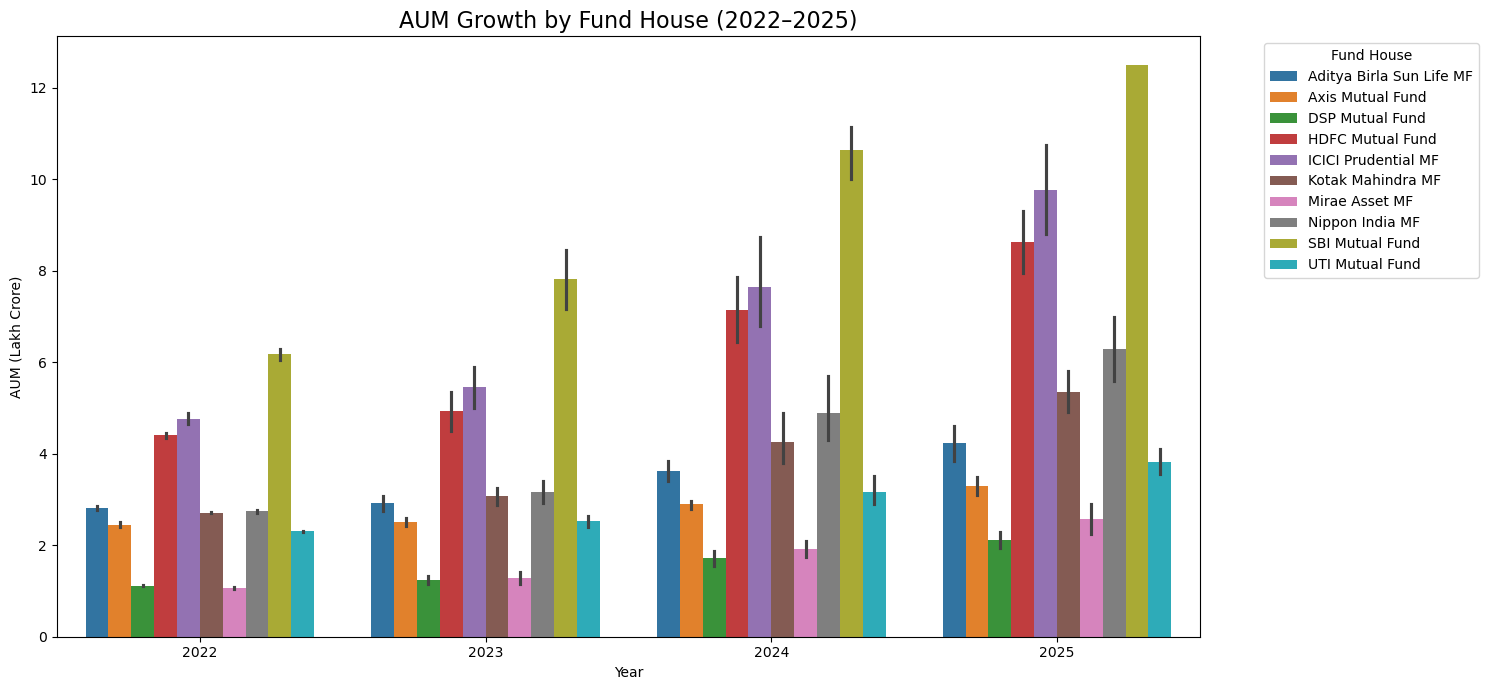

In [27]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=aum_yearly,
    x="year",
    y="aum_lakh_crore",
    hue="fund_house"
)

plt.title("AUM Growth by Fund House (2022–2025)", fontsize=16)
plt.xlabel("Year")
plt.ylabel("AUM (Lakh Crore)")
plt.legend(title="Fund House", bbox_to_anchor=(1.05, 1))
plt.tight_layout()

plt.savefig("charts/aum_growth.png", dpi=300)
plt.show()

In [28]:
sbi_data = aum_yearly[
    aum_yearly["fund_house"].str.contains("SBI", case=False, na=False)
]

print(sbi_data[["date", "fund_house", "aum_lakh_crore"]])

         date       fund_house  aum_lakh_crore
72 2022-03-31  SBI Mutual Fund            6.05
73 2022-09-30  SBI Mutual Fund            6.30
74 2023-03-31  SBI Mutual Fund            7.17
75 2023-09-30  SBI Mutual Fund            8.45
76 2024-03-31  SBI Mutual Fund           10.00
77 2024-09-30  SBI Mutual Fund           10.80
78 2024-12-31  SBI Mutual Fund           11.14
79 2025-03-31  SBI Mutual Fund           12.50
80 2025-12-31  SBI Mutual Fund           12.50


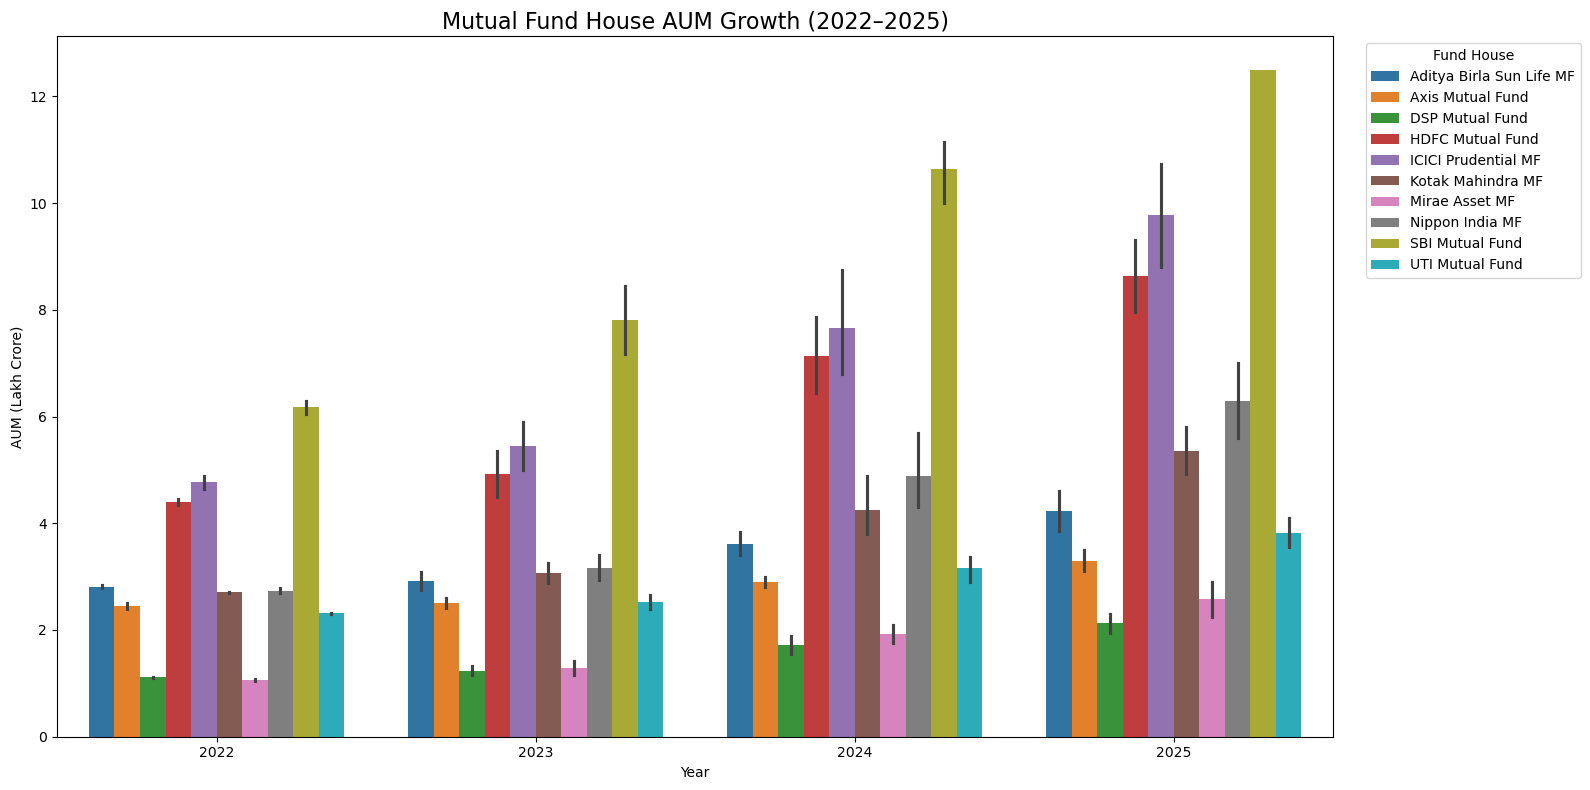

In [29]:
plt.figure(figsize=(16, 8))

sns.barplot(
    data=aum_yearly,
    x="year",
    y="aum_lakh_crore",
    hue="fund_house"
)

plt.title("Mutual Fund House AUM Growth (2022–2025)", fontsize=16)
plt.xlabel("Year")
plt.ylabel("AUM (Lakh Crore)")

plt.legend(
    title="Fund House",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig("charts/aum_growth.png", dpi=300, bbox_inches="tight")

plt.show()

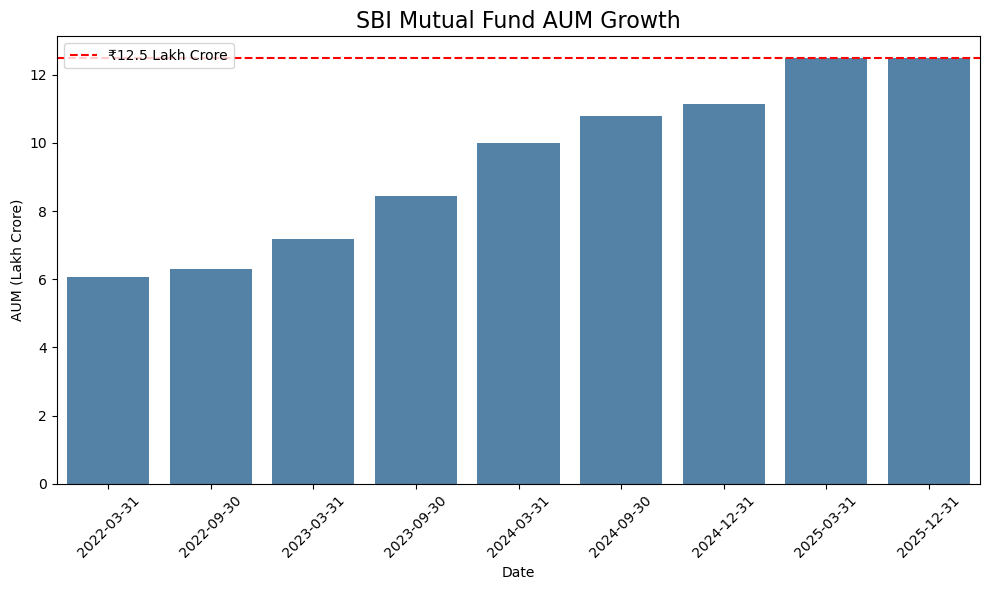

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=sbi_data,
    x="date",
    y="aum_lakh_crore",
    color="steelblue"
)

plt.title("SBI Mutual Fund AUM Growth", fontsize=16)
plt.xlabel("Date")
plt.ylabel("AUM (Lakh Crore)")

plt.xticks(rotation=45)

plt.axhline(
    y=12.5,
    color="red",
    linestyle="--",
    label="₹12.5 Lakh Crore"
)

plt.legend()
plt.tight_layout()

plt.savefig("charts/sbi_aum_growth.png", dpi=300)

plt.show()

In [31]:
# Display first 10 rows

sip.head(10)

,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01-01,11517,4.91,9.10,4.80,NaN
1,2022-02-01,11438,4.93,8.20,4.85,NaN
2,2022-03-01,12328,5.09,10.50,5.01,NaN
3,2022-04-01,11863,5.48,9.52,5.12,NaN
4,2022-05-01,12286,5.55,8.10,5.15,NaN
5,2022-06-01,12276,5.60,7.50,5.18,NaN
6,2022-07-01,12140,5.65,9.21,5.25,NaN
7,2022-08-01,12694,5.71,8.90,5.31,NaN
8,2022-09-01,12976,5.80,9.40,5.41,NaN
9,2022-10-01,13040,5.93,9.52,5.55,NaN


In [32]:
print("SIP Dataset Shape:", sip.shape)

print("\nColumns:")
print(sip.columns)

print("\nMissing Values:")
print(sip.isnull().sum())

SIP Dataset Shape: (48, 6)

Columns:
Index(['month', 'sip_inflow_crore', 'active_sip_accounts_crore',
       'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct'],
      dtype='object')

Missing Values:
month                         0
sip_inflow_crore              0
active_sip_accounts_crore     0
new_sip_accounts_lakh         0
sip_aum_lakh_crore            0
yoy_growth_pct               12
dtype: int64


In [33]:
# Convert month column into datetime

sip["month"] = pd.to_datetime(sip["month"])

# Sort data by month

sip = sip.sort_values("month")

print("SIP Date Conversion Successful!")

print("Start Date:", sip["month"].min())
print("End Date:", sip["month"].max())

SIP Date Conversion Successful!
Start Date: 2022-01-01 00:00:00
End Date: 2025-12-01 00:00:00


In [34]:
fig_sip = px.line(
    sip,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflow Trend (January 2022 – December 2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

# Highlight December 2025

fig_sip.add_annotation(
    x="2025-12-01",
    y=31002,
    text="All-Time High: ₹31,002 Cr",
    showarrow=True,
    arrowhead=2,
    ax=-60,
    ay=-60
)

fig_sip.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=600
)

fig_sip.show()

In [35]:
fig_sip.write_image("charts/sip_inflow.png")

print("SIP Inflow Chart Saved Successfully!")

SIP Inflow Chart Saved Successfully!


In [36]:
fig_sip.write_image("charts/sip_inflow.png")

print("SIP Inflow Chart Saved Successfully!")

SIP Inflow Chart Saved Successfully!


In [37]:
dec_2025 = sip[sip["month"].dt.strftime("%Y-%m") == "2025-12"]

print("December 2025 SIP Inflow:")
print(dec_2025[["month", "sip_inflow_crore"]])

print("\nMaximum SIP Inflow:")
print(sip["sip_inflow_crore"].max())

December 2025 SIP Inflow:
        month  sip_inflow_crore
47 2025-12-01             31002

Maximum SIP Inflow:
31002


In [38]:
fig_sip = px.line(
    sip,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflow Trend (January 2022 – December 2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

fig_sip.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=600
)

fig_sip.show()

In [39]:
import os

os.makedirs("charts", exist_ok=True)

fig_sip.write_image(
    "charts/sip_inflow.png",
    width=1400,
    height=800,
    scale=2
)

print("SIP Inflow Chart Saved Successfully!")

SIP Inflow Chart Saved Successfully!


In [41]:
print("Category Dataset Shape:", category.shape)

print("\nFirst 10 Records:")
display(category.head(10))

print("\nCategories:")
print(category["category"].unique())

print("\nMissing Values:")
print(category.isnull().sum())

Category Dataset Shape: (144, 3)

First 10 Records:


,month,category,net_inflow_crore
0,2024-04-01,ELSS,466.0
1,2024-04-01,Flexi Cap,4947.0
2,2024-04-01,Gilt,784.0
3,2024-04-01,Hybrid,2955.0
4,2024-04-01,Large & Mid Cap,4214.0
5,2024-04-01,Large Cap,2413.0
6,2024-04-01,Liquid,37537.0
7,2024-04-01,Mid Cap,3897.0
8,2024-04-01,Sectoral/Thematic,8052.0
9,2024-04-01,Short Duration,4400.0



Categories:
['ELSS' 'Flexi Cap' 'Gilt' 'Hybrid' 'Large & Mid Cap' 'Large Cap' 'Liquid'
 'Mid Cap' 'Sectoral/Thematic' 'Short Duration' 'Small Cap' 'Value/Contra']

Missing Values:
month               0
category            0
net_inflow_crore    0
dtype: int64


In [43]:
print("Category Dataset Shape:", category.shape)

print("\nFirst 10 Records:")
display(category.head(10))

print("\nCategories:")
print(category["category"].unique())

print("\nMissing Values:")
print(category.isnull().sum())

Category Dataset Shape: (144, 3)

First 10 Records:


,month,category,net_inflow_crore
0,2024-04-01,ELSS,466.0
1,2024-04-01,Flexi Cap,4947.0
2,2024-04-01,Gilt,784.0
3,2024-04-01,Hybrid,2955.0
4,2024-04-01,Large & Mid Cap,4214.0
5,2024-04-01,Large Cap,2413.0
6,2024-04-01,Liquid,37537.0
7,2024-04-01,Mid Cap,3897.0
8,2024-04-01,Sectoral/Thematic,8052.0
9,2024-04-01,Short Duration,4400.0



Categories:
['ELSS' 'Flexi Cap' 'Gilt' 'Hybrid' 'Large & Mid Cap' 'Large Cap' 'Liquid'
 'Mid Cap' 'Sectoral/Thematic' 'Short Duration' 'Small Cap' 'Value/Contra']

Missing Values:
month               0
category            0
net_inflow_crore    0
dtype: int64


In [44]:
category["month"] = pd.to_datetime(category["month"])

category = category.sort_values("month")

print("Category Month Conversion Successful!")

print("Start Date:", category["month"].min())
print("End Date:", category["month"].max())

Category Month Conversion Successful!
Start Date: 2024-04-01 00:00:00
End Date: 2025-03-01 00:00:00


In [45]:
category_pivot = category.pivot_table(
    index="category",
    columns="month",
    values="net_inflow_crore",
    aggfunc="sum"
)

display(category_pivot.head())

print("Pivot Table Shape:", category_pivot.shape)

month,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01
category,,,,,,,,,,,,
ELSS,466.0,553.0,472.0,471.0,499.0,537.0,537.0,571.0,521.0,516.0,437.0,500.0
Flexi Cap,4947.0,5529.0,4478.0,4869.0,5562.0,5397.0,6004.0,6111.0,4654.0,5603.0,6068.0,4767.0
Gilt,784.0,836.0,864.0,959.0,952.0,925.0,898.0,704.0,831.0,744.0,942.0,956.0
Hybrid,2955.0,3487.0,3163.0,3291.0,3684.0,3015.0,3314.0,3264.0,3538.0,2967.0,3360.0,2830.0
Large & Mid Cap,4214.0,4368.0,4610.0,5023.0,5411.0,4528.0,4581.0,5556.0,4878.0,4816.0,5524.0,4243.0


Pivot Table Shape: (12, 12)


In [3]:
plt.figure(figsize=(18, 8))

sns.heatmap(
    category_pivot,
    cmap="YlGnBu",
    linewidths=0.5,
    annot=False
)

plt.title(
    "Monthly Net Inflow by Mutual Fund Category",
    fontsize=16
)

plt.xlabel("Month")
plt.ylabel("Fund Category")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "charts/category_inflow_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'category_pivot' is not defined

<Figure size 1800x800 with 0 Axes>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [5]:
plt.figure(figsize=(18, 8))

sns.heatmap(
    category_pivot,
    cmap="YlGnBu",
    linewidths=0.5,
    annot=False
)

plt.title("Monthly Net Inflow by Mutual Fund Category", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Fund Category")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts/category_inflow_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

NameError: name 'category_pivot' is not defined

<Figure size 1800x800 with 0 Axes>

In [6]:
category_pivot = category.pivot_table(
    index="category",
    columns="month",
    values="net_inflow_crore",
    aggfunc="sum"
)

print("Category Pivot Table Created Successfully!")

display(category_pivot.head())

NameError: name 'category' is not defined

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

print("Libraries Loaded Successfully!")

Libraries Loaded Successfully!


In [8]:
data_path = "data/processed/"

category = pd.read_csv(
    data_path + "category_inflows_cleaned.csv"
)

category["month"] = pd.to_datetime(category["month"])

print("Category Dataset Loaded Successfully!")
display(category.head())

Category Dataset Loaded Successfully!


,month,category,net_inflow_crore
0,2024-04-01,ELSS,466.0
1,2024-04-01,Flexi Cap,4947.0
2,2024-04-01,Gilt,784.0
3,2024-04-01,Hybrid,2955.0
4,2024-04-01,Large & Mid Cap,4214.0


In [9]:
category_pivot = category.pivot_table(
    index="category",
    columns="month",
    values="net_inflow_crore",
    aggfunc="sum"
)

print("Pivot Table Created Successfully!")

display(category_pivot.head())

print("Pivot Table Shape:", category_pivot.shape)

Pivot Table Created Successfully!


month,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01
category,,,,,,,,,,,,
ELSS,466.0,553.0,472.0,471.0,499.0,537.0,537.0,571.0,521.0,516.0,437.0,500.0
Flexi Cap,4947.0,5529.0,4478.0,4869.0,5562.0,5397.0,6004.0,6111.0,4654.0,5603.0,6068.0,4767.0
Gilt,784.0,836.0,864.0,959.0,952.0,925.0,898.0,704.0,831.0,744.0,942.0,956.0
Hybrid,2955.0,3487.0,3163.0,3291.0,3684.0,3015.0,3314.0,3264.0,3538.0,2967.0,3360.0,2830.0
Large & Mid Cap,4214.0,4368.0,4610.0,5023.0,5411.0,4528.0,4581.0,5556.0,4878.0,4816.0,5524.0,4243.0


Pivot Table Shape: (12, 12)


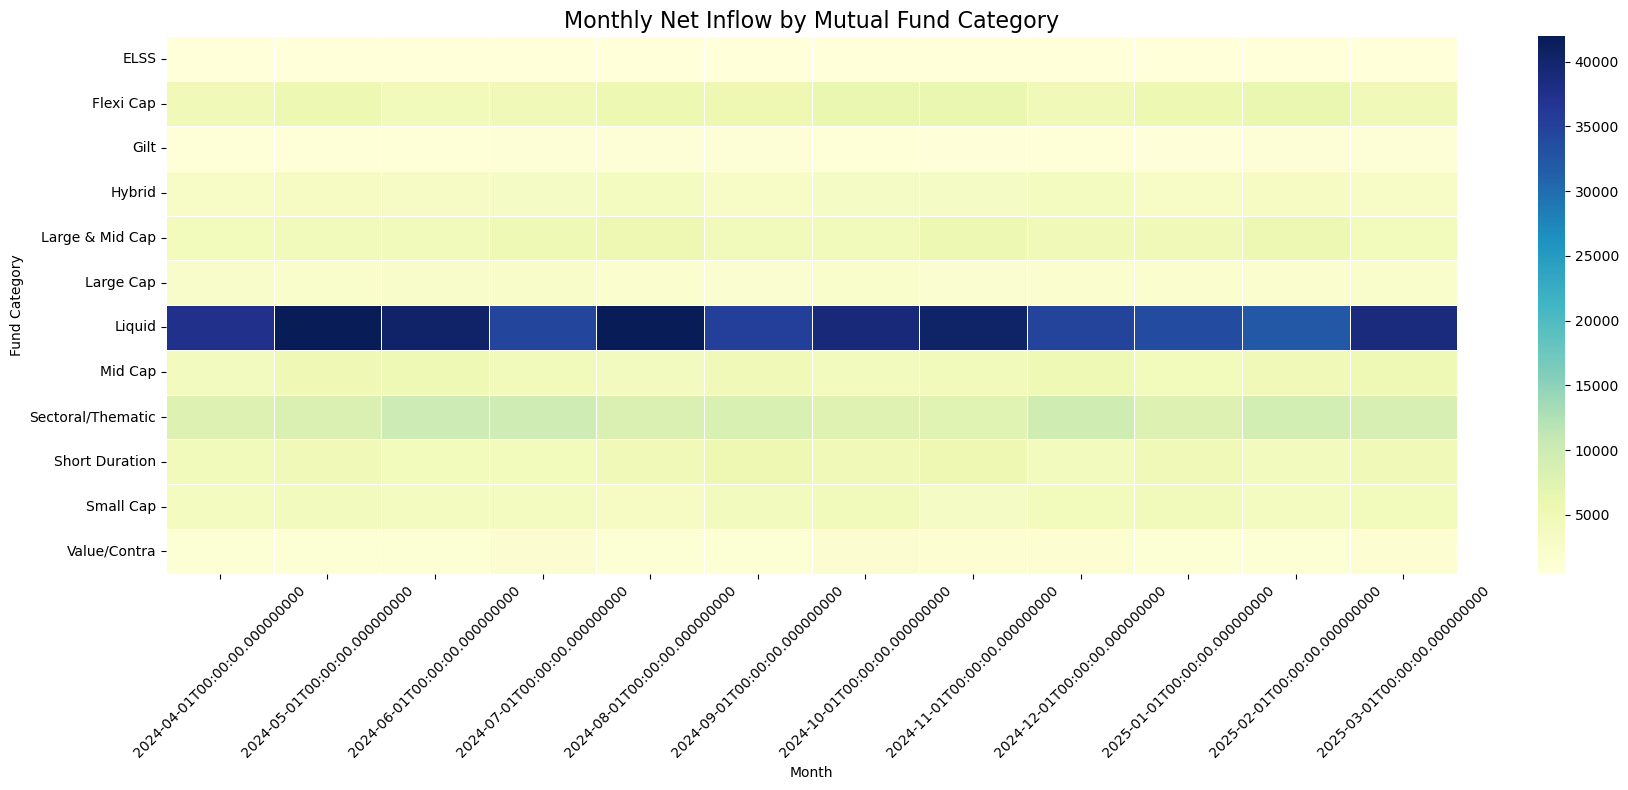

In [10]:
plt.figure(figsize=(18, 8))

sns.heatmap(
    category_pivot,
    cmap="YlGnBu",
    linewidths=0.5,
    annot=False
)

plt.title("Monthly Net Inflow by Mutual Fund Category", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Fund Category")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "charts/category_inflow_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
transactions = pd.read_csv(
    "data/processed/investor_transactions_cleaned.csv"
)

print("Transactions Dataset Shape:", transactions.shape)

print("\nColumns:")
print(transactions.columns.tolist())

print("\nFirst 5 Records:")
display(transactions.head())

print("\nMissing Values:")
print(transactions.isnull().sum())

Transactions Dataset Shape: (13062, 13)

Columns:
['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']

First 5 Records:


,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
1,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending
2,INV002592,2024-01-01,101208,Lumpsum,411860,Madhya Pradesh,Bhopal,B30,26-35,Female,15.7,Mandate,Verified
3,INV000368,2024-01-01,118636,Redemption,339882,Uttar Pradesh,Agra,B30,26-35,Male,16.2,UPI,Verified
4,INV003329,2024-01-01,101207,Lumpsum,295055,Madhya Pradesh,Indore,T30,56+,Male,25.2,Mandate,Verified



Missing Values:
investor_id           0
transaction_date      0
amfi_code             0
transaction_type      0
amount_inr            0
state                 0
city                  0
city_tier             0
age_group             0
gender                0
annual_income_lakh    0
payment_mode          0
kyc_status            0
dtype: int64


In [12]:
print("Age Groups:")
print(transactions["age_group"].value_counts())

print("\nUnique Age Groups:")
print(transactions["age_group"].unique())

Age Groups:
age_group
26-35    5400
36-45    3220
18-25    1967
46-55    1479
56+       996
Name: count, dtype: int64

Unique Age Groups:
['18-25' '26-35' '56+' '36-45' '46-55']


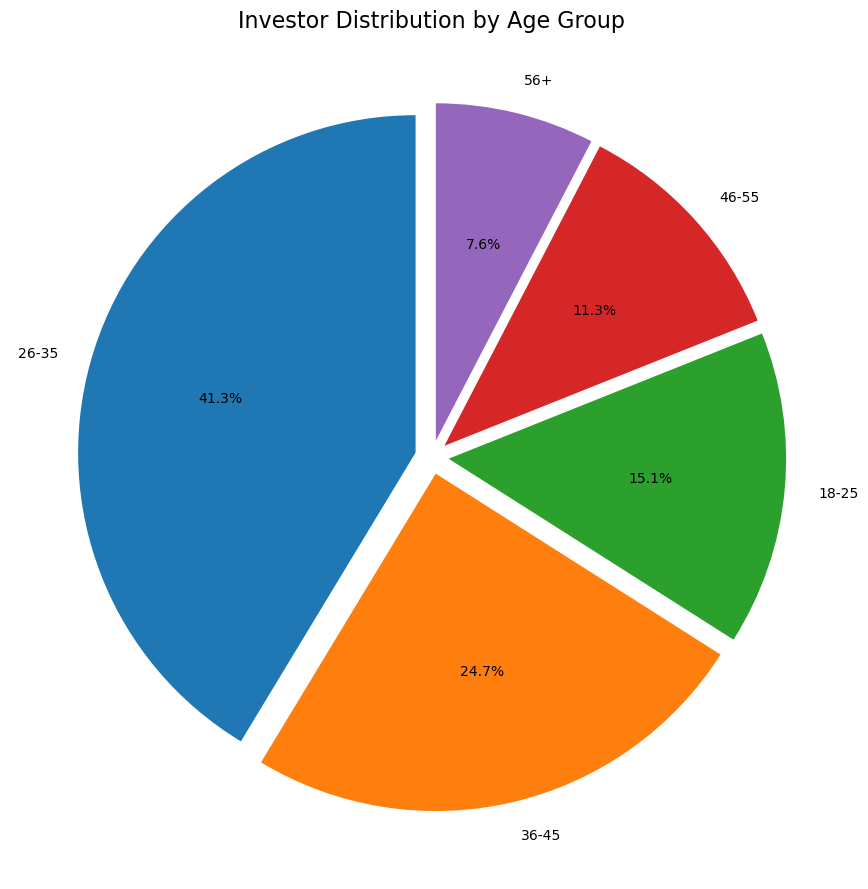

In [13]:
age_counts = transactions["age_group"].value_counts()

plt.figure(figsize=(9, 9))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05] * len(age_counts)
)

plt.title("Investor Distribution by Age Group", fontsize=16)

plt.tight_layout()

plt.savefig(
    "charts/age_group_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
gender_counts = transactions["gender"].value_counts()

print(gender_counts)

gender
Male      8687
Female    4375
Name: count, dtype: int64


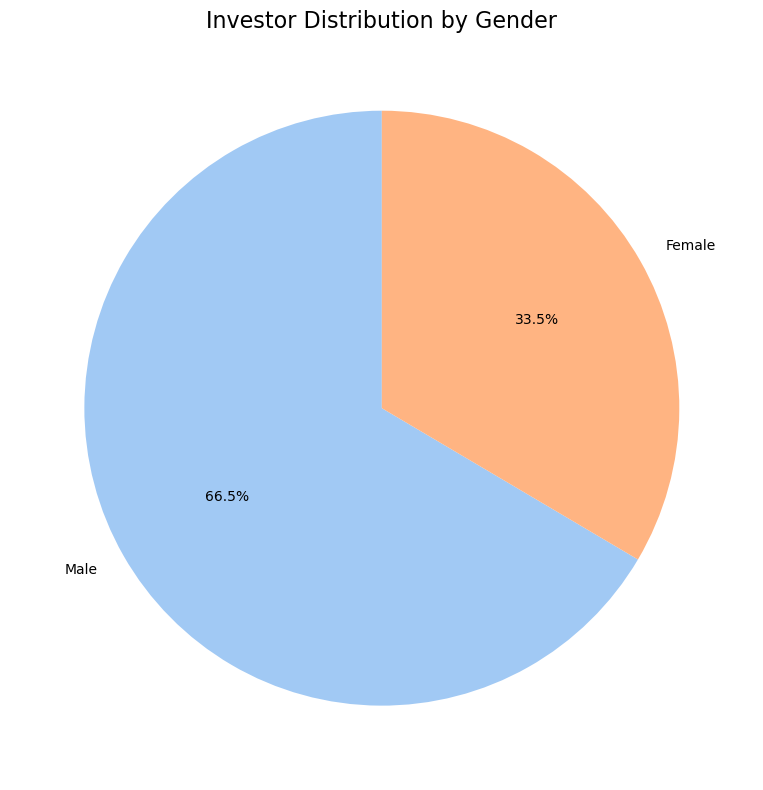

In [15]:
gender_counts = transactions["gender"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("pastel")
)

plt.title("Investor Distribution by Gender", fontsize=16)

plt.tight_layout()

plt.savefig(
    "charts/gender_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

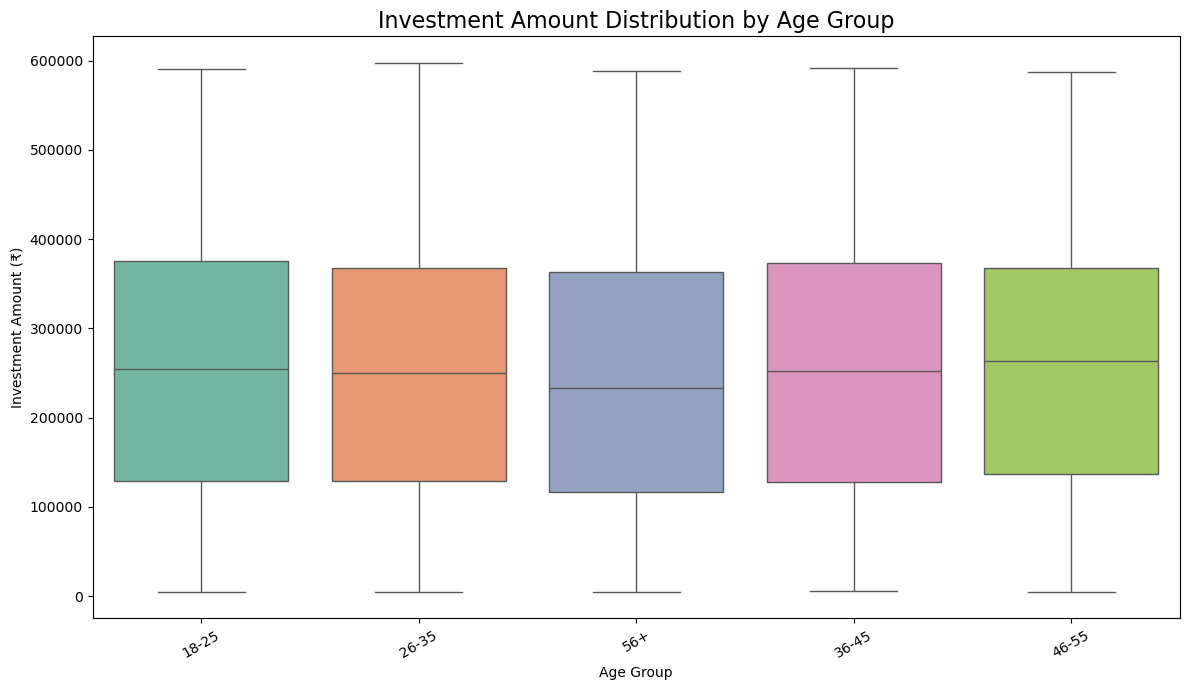

In [16]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=transactions,
    x="age_group",
    y="amount_inr",
    hue="age_group",
    palette="Set2",
    legend=False
)

plt.title("Investment Amount Distribution by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Investment Amount (₹)")
plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    "charts/age_group_investment_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
print("Number of States:", transactions["state"].nunique())

print("\nTop 10 States by Investment Amount:")

state_investment = (
    transactions.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
)

display(state_investment.head(10))

Number of States: 12

Top 10 States by Investment Amount:


state
Tamil Nadu        296772869
Punjab            295640395
Madhya Pradesh    287630250
Rajasthan         282101589
Gujarat           279980036
West Bengal       279686745
Delhi             272519796
Telangana         271599068
Uttar Pradesh     267834015
Haryana           261457658
Name: amount_inr, dtype: int64

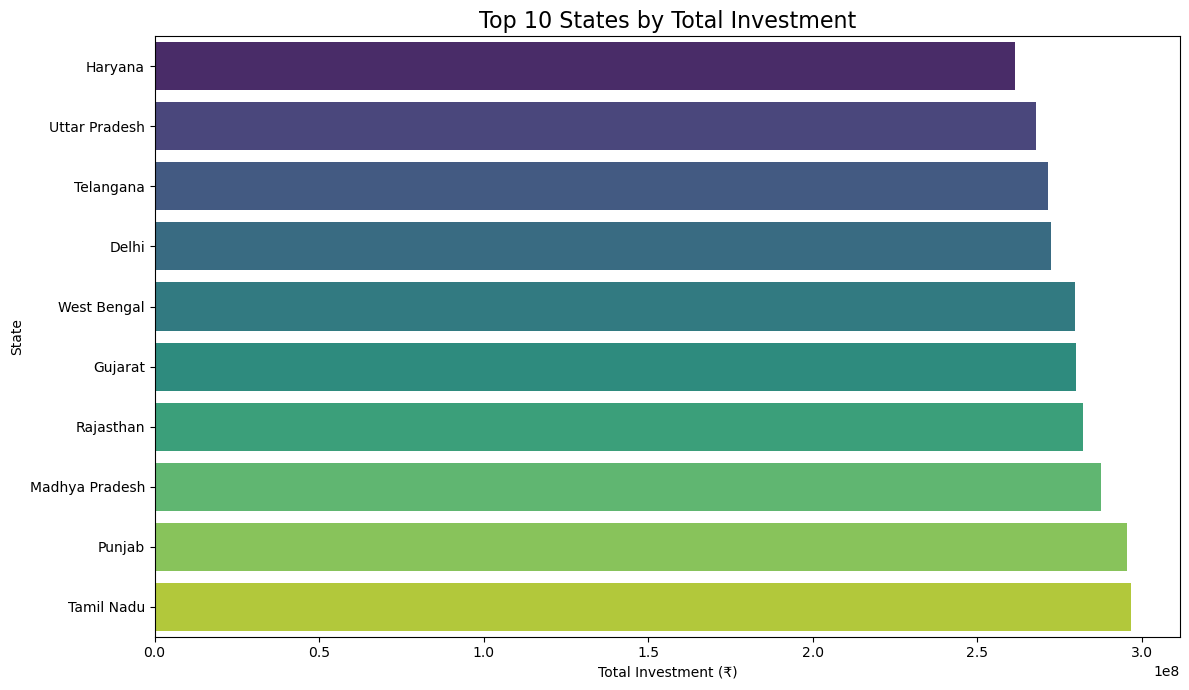

In [18]:
top_10_states = state_investment.head(10).sort_values()

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index,
    hue=top_10_states.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 States by Total Investment", fontsize=16)
plt.xlabel("Total Investment (₹)")
plt.ylabel("State")

plt.tight_layout()

plt.savefig(
    "charts/state_wise_investment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
print("City Tier Distribution:")

print(transactions["city_tier"].value_counts())

print("\nUnique City Tiers:")

print(transactions["city_tier"].unique())

City Tier Distribution:
city_tier
T30    8596
B30    4466
Name: count, dtype: int64

Unique City Tiers:
['B30' 'T30']


In [20]:
city_tier_investment = (
    transactions.groupby("city_tier")["amount_inr"]
    .sum()
)

print(city_tier_investment)

city_tier
B30    1130020770
T30    2174326169
Name: amount_inr, dtype: int64


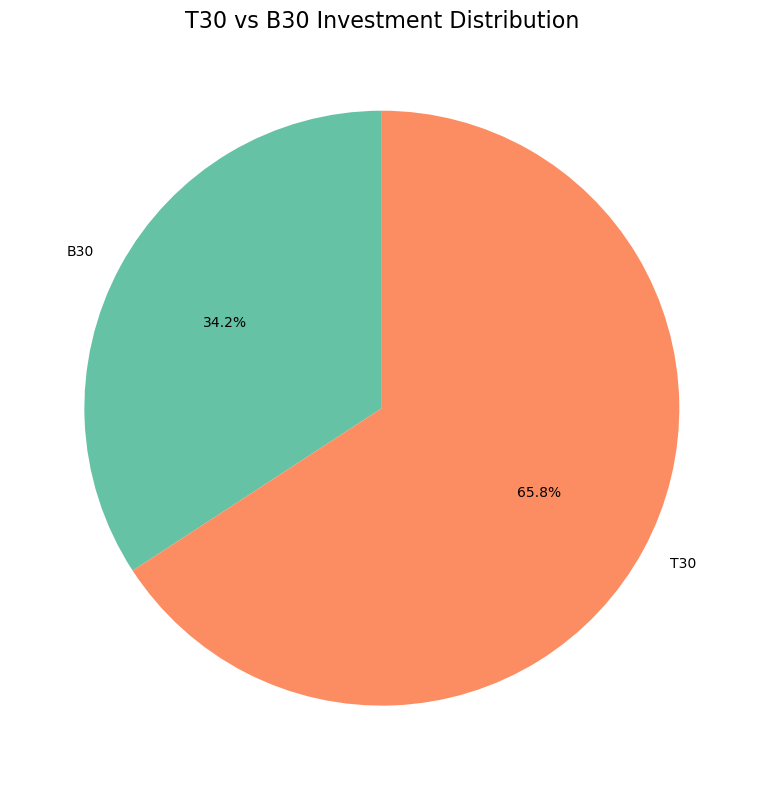

In [21]:
plt.figure(figsize=(8, 8))

plt.pie(
    city_tier_investment,
    labels=city_tier_investment.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2")
)

plt.title("T30 vs B30 Investment Distribution", fontsize=16)

plt.tight_layout()

plt.savefig(
    "charts/t30_b30_investment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
folio = pd.read_csv(
    "data/processed/industry_folio_count_cleaned.csv"
)

print("Folio Dataset Shape:", folio.shape)

print("\nFirst 5 Records:")
display(folio.head())

print("\nColumns:")
print(folio.columns.tolist())

print("\nMissing Values:")
print(folio.isnull().sum())

Folio Dataset Shape: (21, 6)

First 5 Records:


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01-01,13.26,9.28,1.86,0.80,1.33
1,2022-04-01,13.91,9.74,1.95,0.83,1.39
2,2022-07-01,13.85,9.69,1.94,0.83,1.38
3,2022-10-01,14.12,9.88,1.98,0.85,1.41
4,2023-01-01,14.81,10.37,2.07,0.89,1.48



Columns:
['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']

Missing Values:
month                  0
total_folios_crore     0
equity_folios_crore    0
debt_folios_crore      0
hybrid_folios_crore    0
others_folios_crore    0
dtype: int64


In [23]:
folio["month"] = pd.to_datetime(folio["month"])

folio = folio.sort_values("month")

print("Folio Date Conversion Successful!")

print("Start Date:", folio["month"].min())
print("End Date:", folio["month"].max())

Folio Date Conversion Successful!
Start Date: 2022-01-01 00:00:00
End Date: 2025-12-01 00:00:00


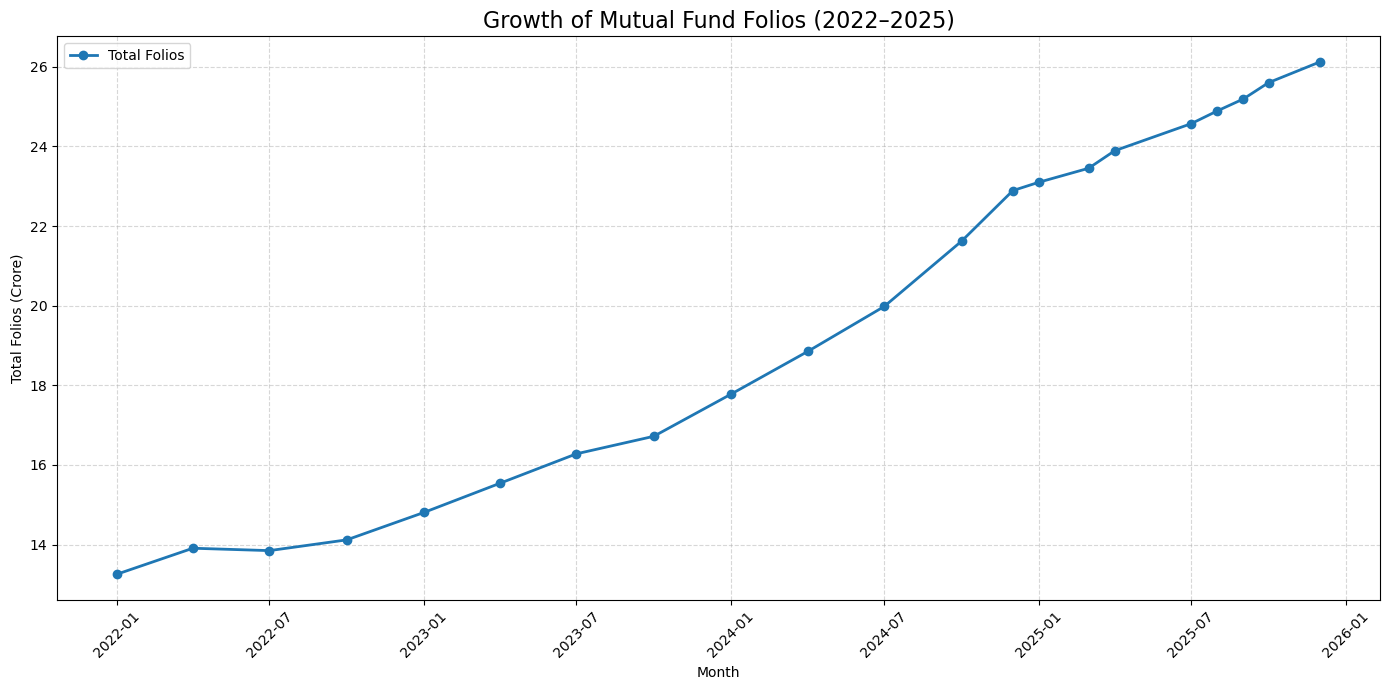

In [24]:
plt.figure(figsize=(14, 7))

plt.plot(
    folio["month"],
    folio["total_folios_crore"],
    marker="o",
    linewidth=2,
    label="Total Folios"
)

plt.title("Growth of Mutual Fund Folios (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "charts/folio_count_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

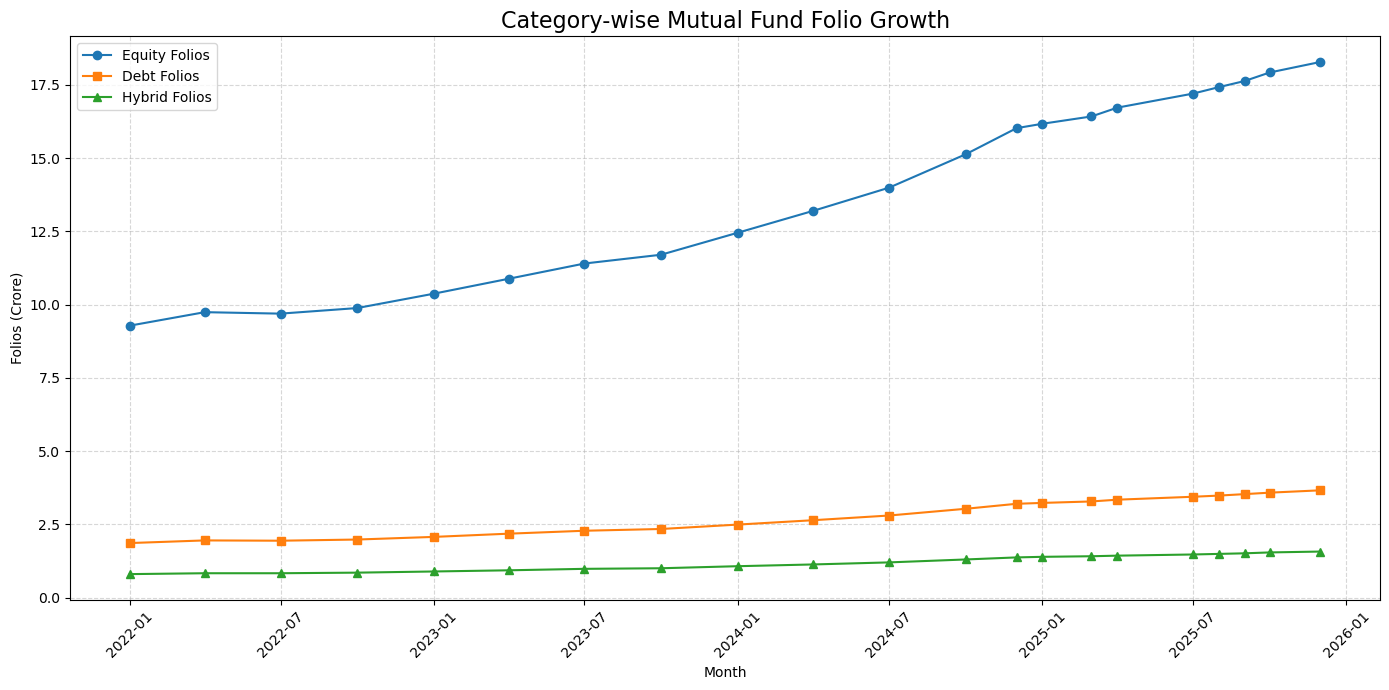

In [25]:
plt.figure(figsize=(14, 7))

plt.plot(
    folio["month"],
    folio["equity_folios_crore"],
    marker="o",
    label="Equity Folios"
)

plt.plot(
    folio["month"],
    folio["debt_folios_crore"],
    marker="s",
    label="Debt Folios"
)

plt.plot(
    folio["month"],
    folio["hybrid_folios_crore"],
    marker="^",
    label="Hybrid Folios"
)

plt.title("Category-wise Mutual Fund Folio Growth", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Folios (Crore)")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "charts/category_wise_folio_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
nav = pd.read_csv(
    "data/processed/nav_history_cleaned.csv"
)

nav["date"] = pd.to_datetime(nav["date"])

print("NAV Dataset Shape:", nav.shape)

print("\nFirst 5 Records:")
display(nav.head())

print("\nUnique Schemes:", nav["amfi_code"].nunique())

NAV Dataset Shape: (46000, 3)

First 5 Records:


,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639



Unique Schemes: 40


In [27]:
fund = pd.read_csv(
    "data/processed/fund_master_cleaned.csv"
)

nav_merged = pd.merge(
    nav,
    fund[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

print("NAV and Fund Master Merged Successfully!")

print("\nAvailable Schemes:")
display(
    nav_merged[["amfi_code", "scheme_name"]]
    .drop_duplicates()
    .head(10)
)

print("\nTotal Schemes:", nav_merged["scheme_name"].nunique())

NAV and Fund Master Merged Successfully!

Available Schemes:


,amfi_code,scheme_name
0,100016,HDFC Top 100 Fund - Regular Plan - Growth
1150,100025,HDFC Short Term Debt Fund - Regular - Growth
2300,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...
3450,101206,ABSL Frontline Equity Fund - Regular - Growth
4600,101207,ABSL Small Cap Fund - Regular - Growth
5750,101208,ABSL Liquid Fund - Regular - Growth
6900,102885,UTI Nifty 50 Index Fund - Regular - Growth
8050,102886,UTI Mid Cap Fund - Regular - Growth
9200,102887,UTI Flexi Cap Fund - Regular - Growth
10350,118632,Nippon India Large Cap Fund - Regular - Growth



Total Schemes: 40


In [28]:
selected_schemes = (
    nav_merged["scheme_name"]
    .dropna()
    .unique()[:10]
)

print("Selected 10 Schemes:")
for i, scheme in enumerate(selected_schemes, 1):
    print(i, scheme)

Selected 10 Schemes:
1 HDFC Top 100 Fund - Regular Plan - Growth
2 HDFC Short Term Debt Fund - Regular - Growth
3 HDFC Mid-Cap Opportunities Fund - Regular - Growth
4 ABSL Frontline Equity Fund - Regular - Growth
5 ABSL Small Cap Fund - Regular - Growth
6 ABSL Liquid Fund - Regular - Growth
7 UTI Nifty 50 Index Fund - Regular - Growth
8 UTI Mid Cap Fund - Regular - Growth
9 UTI Flexi Cap Fund - Regular - Growth
10 Nippon India Large Cap Fund - Regular - Growth


In [29]:
nav_10 = nav_merged[
    nav_merged["scheme_name"].isin(selected_schemes)
].copy()

nav_10 = nav_10.sort_values(["scheme_name", "date"])

nav_10["daily_return"] = (
    nav_10.groupby("scheme_name")["nav"]
    .pct_change() * 100
)

print("Daily Returns Calculated Successfully!")

display(nav_10.head(10))

print("\nTotal Records:", nav_10.shape[0])

Daily Returns Calculated Successfully!


,amfi_code,date,nav,scheme_name,daily_return
3450,101206,2022-01-03,305.0996,ABSL Frontline Equity Fund - Regular - Growth,NaN
3451,101206,2022-01-04,305.4514,ABSL Frontline Equity Fund - Regular - Growth,0.115307
3452,101206,2022-01-05,306.6324,ABSL Frontline Equity Fund - Regular - Growth,0.386641
3453,101206,2022-01-06,305.9800,ABSL Frontline Equity Fund - Regular - Growth,-0.212763
3454,101206,2022-01-07,304.0480,ABSL Frontline Equity Fund - Regular - Growth,-0.631414
3455,101206,2022-01-10,307.5591,ABSL Frontline Equity Fund - Regular - Growth,1.154785
3456,101206,2022-01-11,309.4372,ABSL Frontline Equity Fund - Regular - Growth,0.610647
3457,101206,2022-01-12,313.2022,ABSL Frontline Equity Fund - Regular - Growth,1.216725
3458,101206,2022-01-13,310.7396,ABSL Frontline Equity Fund - Regular - Growth,-0.786265
3459,101206,2022-01-14,308.9641,ABSL Frontline Equity Fund - Regular - Growth,-0.571379



Total Records: 11500


In [30]:
returns_pivot = nav_10.pivot_table(
    index="date",
    columns="scheme_name",
    values="daily_return"
)

correlation_matrix = returns_pivot.corr()

print("Correlation Matrix Created Successfully!")

display(correlation_matrix.round(2))

Correlation Matrix Created Successfully!


scheme_name,ABSL Frontline Equity Fund - Regular - Growth,ABSL Liquid Fund - Regular - Growth,ABSL Small Cap Fund - Regular - Growth,HDFC Mid-Cap Opportunities Fund - Regular - Growth,HDFC Short Term Debt Fund - Regular - Growth,HDFC Top 100 Fund - Regular Plan - Growth,Nippon India Large Cap Fund - Regular - Growth,UTI Flexi Cap Fund - Regular - Growth,UTI Mid Cap Fund - Regular - Growth,UTI Nifty 50 Index Fund - Regular - Growth
scheme_name,,,,,,,,,,
ABSL Frontline Equity Fund - Regular - Growth,1.00,-0.03,0.01,-0.02,0.02,0.03,-0.01,-0.01,0.01,0.00
ABSL Liquid Fund - Regular - Growth,-0.03,1.00,-0.01,0.01,0.02,-0.03,0.00,0.04,0.01,-0.00
ABSL Small Cap Fund - Regular - Growth,0.01,-0.01,1.00,0.00,-0.01,0.02,0.04,0.00,0.00,-0.01
HDFC Mid-Cap Opportunities Fund - Regular - Growth,-0.02,0.01,0.00,1.00,0.00,-0.00,-0.01,-0.04,-0.02,-0.03
HDFC Short Term Debt Fund - Regular - Growth,0.02,0.02,-0.01,0.00,1.00,0.05,-0.01,-0.01,0.01,-0.00
HDFC Top 100 Fund - Regular Plan - Growth,0.03,-0.03,0.02,-0.00,0.05,1.00,-0.03,-0.02,-0.01,-0.09
Nippon India Large Cap Fund - Regular - Growth,-0.01,0.00,0.04,-0.01,-0.01,-0.03,1.00,0.00,-0.04,-0.00
UTI Flexi Cap Fund - Regular - Growth,-0.01,0.04,0.00,-0.04,-0.01,-0.02,0.00,1.00,-0.01,-0.04
UTI Mid Cap Fund - Regular - Growth,0.01,0.01,0.00,-0.02,0.01,-0.01,-0.04,-0.01,1.00,0.02


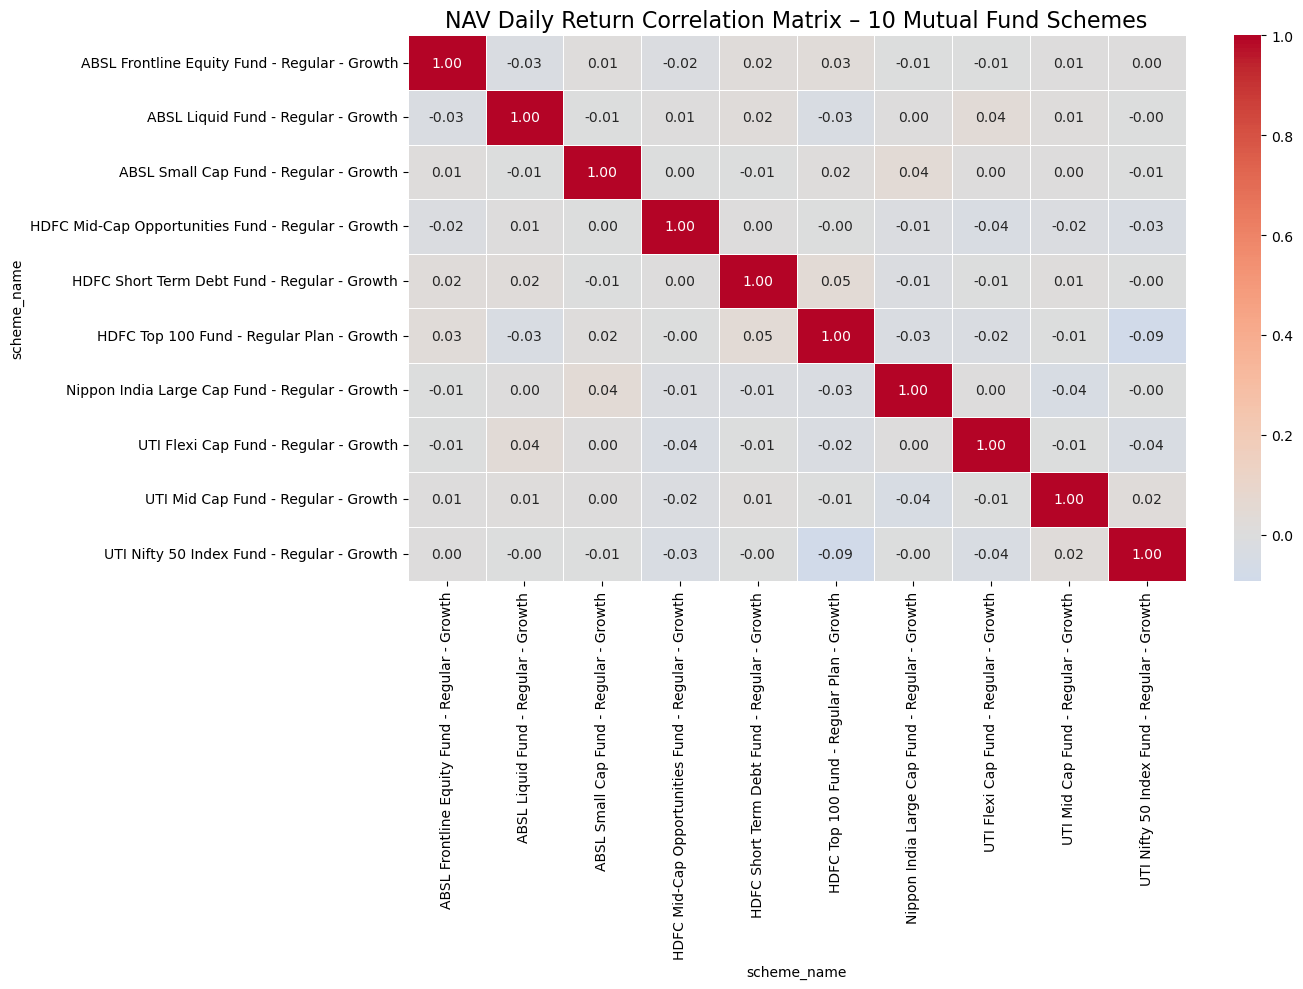

In [31]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title(
    "NAV Daily Return Correlation Matrix – 10 Mutual Fund Schemes",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "charts/nav_return_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
holdings = pd.read_csv(
    "data/processed/portfolio_holdings_cleaned.csv"
)

print("Portfolio Holdings Shape:", holdings.shape)

print("\nFirst 10 Records:")
display(holdings.head(10))

print("\nAvailable Sectors:")
print(holdings["sector"].unique())

print("\nMissing Values:")
print(holdings.isnull().sum())

Portfolio Holdings Shape: (322, 8)

First 10 Records:


,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31
5,119551,NTPC,NTPC Ltd,Utilities,7.48,897.70,2913.66,2025-12-31
6,119551,DIVISLAB,Divi's Laboratories,Pharma,3.21,286.44,3964.01,2025-12-31
7,119551,BHARTIARTL,Bharti Airtel Ltd,Telecom,13.94,452.19,5013.45,2025-12-31
8,119551,HCLTECH,HCL Technologies Ltd,IT,18.22,177.35,6024.13,2025-12-31
9,119551,MARUTI,Maruti Suzuki India Ltd,Automobile,7.20,1982.33,5461.85,2025-12-31



Available Sectors:
['Utilities' 'Banking' 'Diversified' 'Pharma' 'Paints' 'Telecom' 'IT'
 'Automobile' 'NBFC' 'Cement' 'Energy' 'Consumer Goods' 'FMCG'
 'Infrastructure']

Missing Values:
amfi_code            0
stock_symbol         0
stock_name           0
sector               0
weight_pct           0
market_value_cr      0
current_price_inr    0
portfolio_date       0
dtype: int64


In [33]:
fund = pd.read_csv(
    "data/processed/fund_master_cleaned.csv"
)

print("Available Fund Categories:")
print(fund["category"].value_counts())

print("\nAvailable Sub-Categories:")
print(fund["sub_category"].unique())

Available Fund Categories:
category
Equity    34
Debt       6
Name: count, dtype: int64

Available Sub-Categories:
['Large Cap' 'Small Cap' 'Gilt' 'Mid Cap' 'Short Duration' 'Value'
 'Liquid' 'Index/ETF' 'Flexi Cap' 'Index' 'Large & Mid Cap' 'ELSS']


In [34]:
equity_funds = fund[
    fund["category"] == "Equity"
].copy()

print("Total Equity Funds:", equity_funds.shape[0])

print("\nEquity Fund Details:")
display(
    equity_funds[
        ["amfi_code", "scheme_name", "category", "sub_category"]
    ].head(10)
)

Total Equity Funds: 34

Equity Fund Details:


,amfi_code,scheme_name,category,sub_category
0,119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap
1,119552,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap
2,119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap
3,119599,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap
5,100016,HDFC Top 100 Fund - Regular Plan - Growth,Equity,Large Cap
6,125497,HDFC Top 100 Fund - Direct Plan - Growth,Equity,Large Cap
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap
8,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Equity,Mid Cap
10,120503,ICICI Pru Bluechip Fund - Regular - Growth,Equity,Large Cap
11,120504,ICICI Pru Bluechip Fund - Direct - Growth,Equity,Large Cap


In [35]:
fig_sip = px.line(
    sip,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflow Trend (2022–2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

# December 2025 highlight
if not dec_2025.empty:
    dec_value = dec_2025["sip_inflow_crore"].iloc[0]

    fig_sip.add_annotation(
        x=dec_2025["month"].iloc[0],
        y=dec_value,
        text=f"Dec 2025: ₹{dec_value:,.0f} Cr",
        showarrow=True,
        arrowhead=2
    )

fig_sip.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=600
)

fig_sip.show()

NameError: name 'sip' is not defined

In [36]:
import pandas as pd

data_path = "data/processed/"

sip = pd.read_csv(data_path + "monthly_sip_inflows_cleaned.csv")

sip["month"] = pd.to_datetime(sip["month"])
sip = sip.sort_values("month")

print("SIP Dataset Loaded Successfully!")
print(sip.head())

SIP Dataset Loaded Successfully!
       month  sip_inflow_crore  active_sip_accounts_crore  \
0 2022-01-01             11517                       4.91   
1 2022-02-01             11438                       4.93   
2 2022-03-01             12328                       5.09   
3 2022-04-01             11863                       5.48   
4 2022-05-01             12286                       5.55   

   new_sip_accounts_lakh  sip_aum_lakh_crore  yoy_growth_pct  
0                   9.10                4.80             NaN  
1                   8.20                4.85             NaN  
2                  10.50                5.01             NaN  
3                   9.52                5.12             NaN  
4                   8.10                5.15             NaN  


In [37]:
fig_sip = px.line(
    sip,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflow Trend (2022–2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

dec_2025 = sip[sip["month"].dt.strftime("%Y-%m") == "2025-12"]

if not dec_2025.empty:
    dec_value = dec_2025["sip_inflow_crore"].iloc[0]

    fig_sip.add_annotation(
        x=dec_2025["month"].iloc[0],
        y=dec_value,
        text=f"Dec 2025: ₹{dec_value:,.0f} Cr",
        showarrow=True,
        arrowhead=2
    )

fig_sip.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=600
)

fig_sip.show()

In [38]:
import os

os.makedirs("charts", exist_ok=True)

fig_sip.write_image(
    "charts/sip_inflow.png",
    width=1400,
    height=700,
    scale=2
)

print("SIP Inflow Chart Saved Successfully!")

SIP Inflow Chart Saved Successfully!


In [39]:
print("Category Dataset Shape:", category.shape)

print("\nCategory Dataset:")
print(category.head(10))

print("\nAvailable Categories:")
print(category["category"].unique())

Category Dataset Shape: (144, 3)

Category Dataset:
       month           category  net_inflow_crore
0 2024-04-01               ELSS             466.0
1 2024-04-01          Flexi Cap            4947.0
2 2024-04-01               Gilt             784.0
3 2024-04-01             Hybrid            2955.0
4 2024-04-01    Large & Mid Cap            4214.0
5 2024-04-01          Large Cap            2413.0
6 2024-04-01             Liquid           37537.0
7 2024-04-01            Mid Cap            3897.0
8 2024-04-01  Sectoral/Thematic            8052.0
9 2024-04-01     Short Duration            4400.0

Available Categories:
['ELSS' 'Flexi Cap' 'Gilt' 'Hybrid' 'Large & Mid Cap' 'Large Cap' 'Liquid'
 'Mid Cap' 'Sectoral/Thematic' 'Short Duration' 'Small Cap' 'Value/Contra']


In [40]:
category = pd.read_csv(
    "data/processed/category_inflows_cleaned.csv"
)

category["month"] = pd.to_datetime(category["month"])

category = category.sort_values("month")

print("Category Dataset Loaded Successfully!")
print(category.head())

Category Dataset Loaded Successfully!
        month        category  net_inflow_crore
0  2024-04-01            ELSS             466.0
11 2024-04-01    Value/Contra            1328.0
10 2024-04-01       Small Cap            3533.0
9  2024-04-01  Short Duration            4400.0
7  2024-04-01         Mid Cap            3897.0


In [41]:
category_pivot = category.pivot_table(
    index="category",
    columns="month",
    values="net_inflow_crore",
    aggfunc="sum"
)

print("Category Pivot Table:")
display(category_pivot)

Category Pivot Table:


month,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01
category,,,,,,,,,,,,
ELSS,466.0,553.0,472.0,471.0,499.0,537.0,537.0,571.0,521.0,516.0,437.0,500.0
Flexi Cap,4947.0,5529.0,4478.0,4869.0,5562.0,5397.0,6004.0,6111.0,4654.0,5603.0,6068.0,4767.0
Gilt,784.0,836.0,864.0,959.0,952.0,925.0,898.0,704.0,831.0,744.0,942.0,956.0
Hybrid,2955.0,3487.0,3163.0,3291.0,3684.0,3015.0,3314.0,3264.0,3538.0,2967.0,3360.0,2830.0
Large & Mid Cap,4214.0,4368.0,4610.0,5023.0,5411.0,4528.0,4581.0,5556.0,4878.0,4816.0,5524.0,4243.0
Large Cap,2413.0,2076.0,2519.0,2574.0,1940.0,1879.0,2255.0,1870.0,1923.0,2025.0,1925.0,2234.0
Liquid,37537.0,41872.0,40486.0,34643.0,41952.0,35308.0,39091.0,40506.0,34933.0,33892.0,32374.0,38681.0
Mid Cap,3897.0,5300.0,5047.0,4548.0,3899.0,4960.0,4106.0,4336.0,5023.0,4316.0,4819.0,5061.0
Sectoral/Thematic,8052.0,8354.0,10030.0,9896.0,8360.0,8518.0,7680.0,7397.0,9820.0,7893.0,9215.0,8614.0


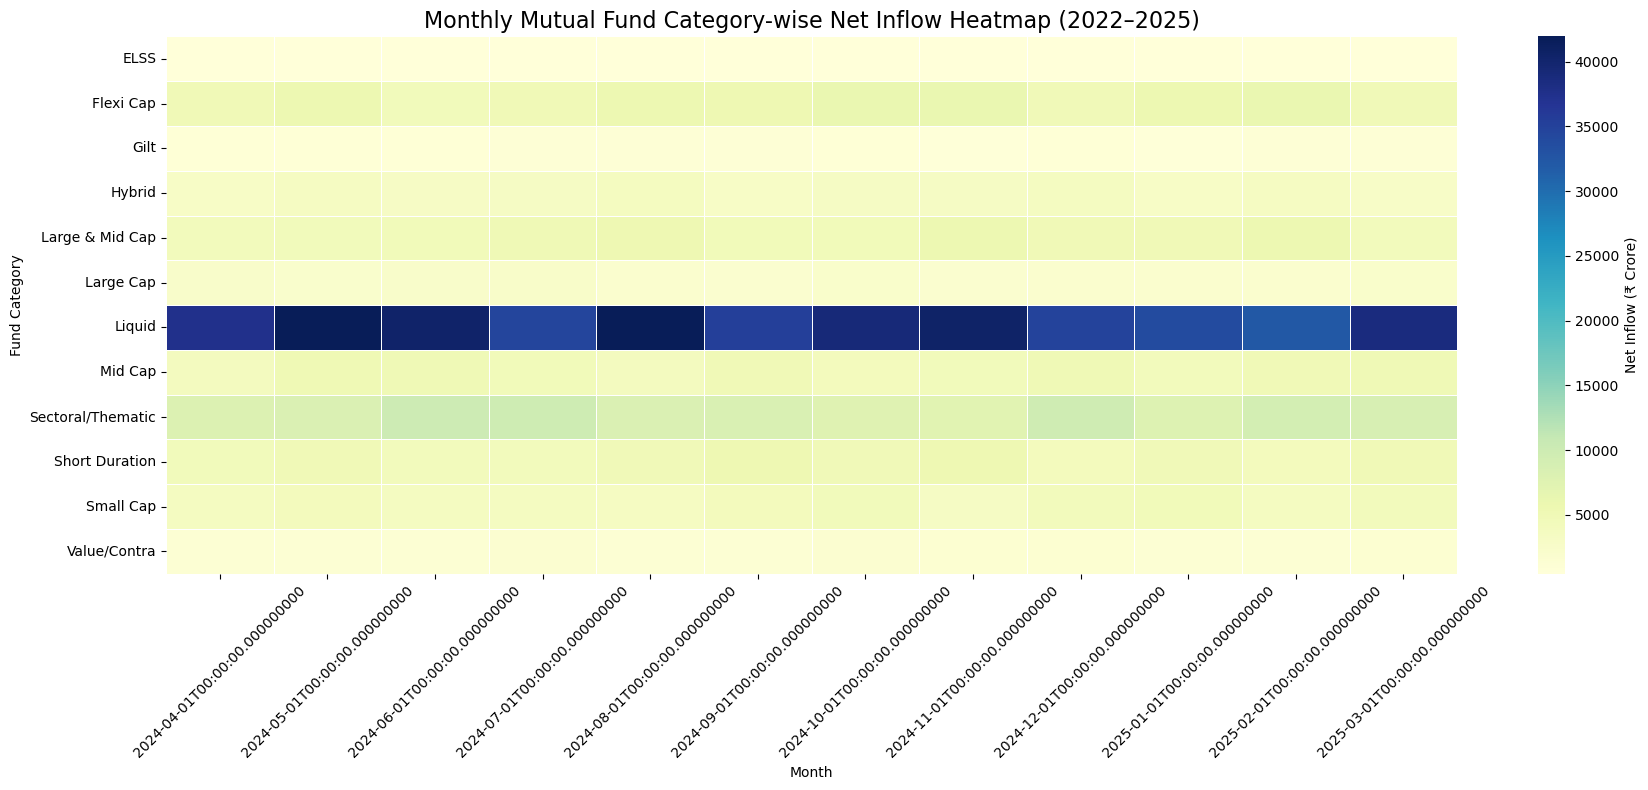

In [42]:
plt.figure(figsize=(18, 8))

sns.heatmap(
    category_pivot,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Monthly Mutual Fund Category-wise Net Inflow Heatmap (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Fund Category")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

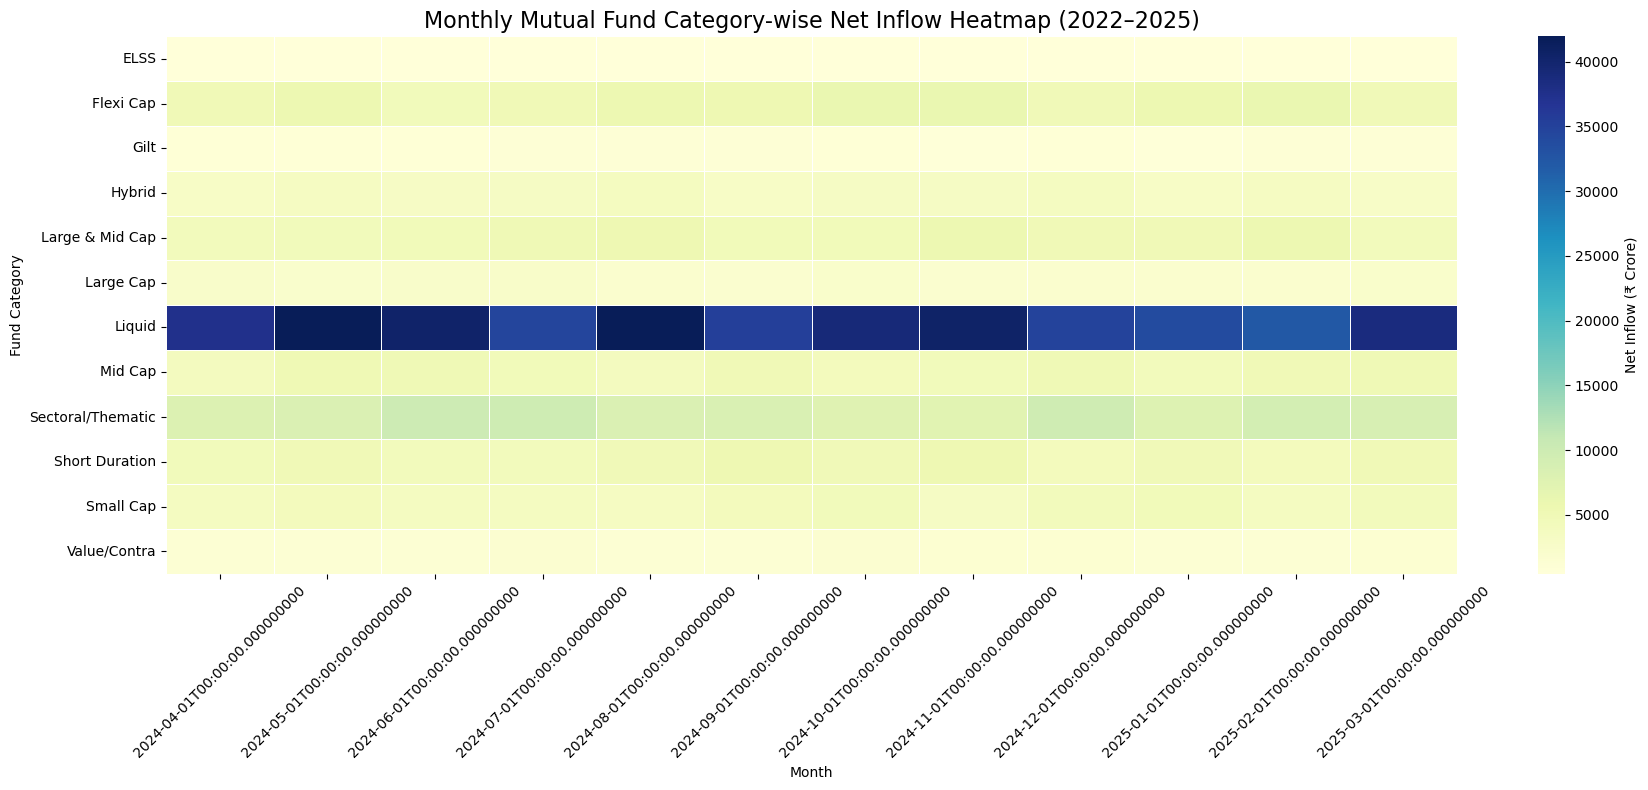

Category Heatmap Saved Successfully!


In [43]:
plt.figure(figsize=(18, 8))

sns.heatmap(
    category_pivot,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Monthly Mutual Fund Category-wise Net Inflow Heatmap (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Fund Category")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts/category_inflow_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

print("Category Heatmap Saved Successfully!")

In [44]:
transactions = pd.read_csv(
    "data/processed/investor_transactions_cleaned.csv"
)

print("Transactions Dataset Shape:", transactions.shape)

print("\nAvailable Columns:")
print(transactions.columns.tolist())

print("\nAge Groups:")
print(transactions["age_group"].value_counts())

print("\nGender Distribution:")
print(transactions["gender"].value_counts())

Transactions Dataset Shape: (13062, 13)

Available Columns:
['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']

Age Groups:
age_group
26-35    5400
36-45    3220
18-25    1967
46-55    1479
56+       996
Name: count, dtype: int64

Gender Distribution:
gender
Male      8687
Female    4375
Name: count, dtype: int64


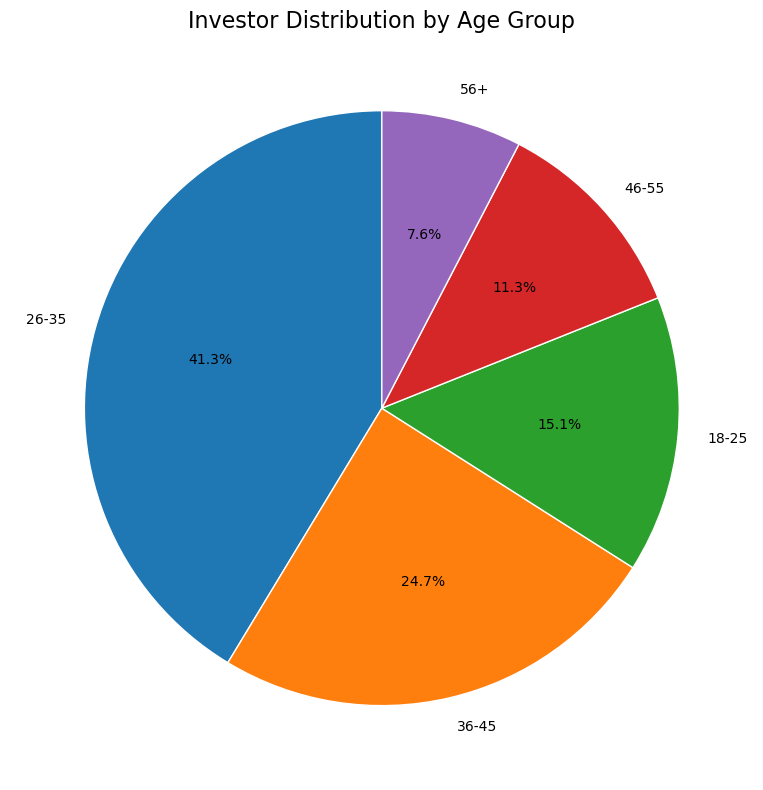

In [45]:
age_counts = transactions["age_group"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Distribution by Age Group", fontsize=16)
plt.tight_layout()

plt.show()

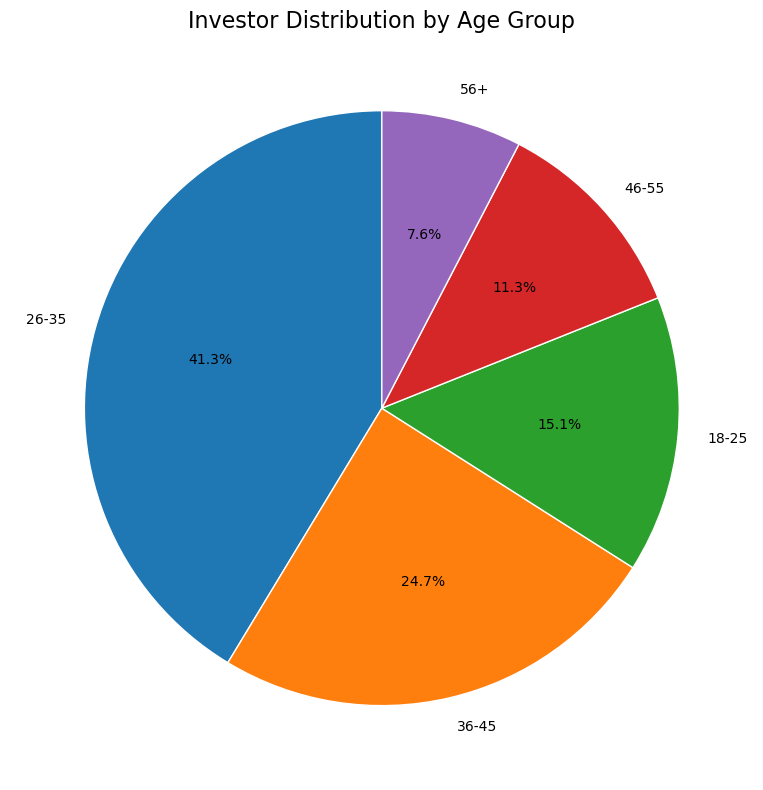

Age Distribution Chart Saved Successfully!


In [46]:
plt.figure(figsize=(8, 8))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Distribution by Age Group", fontsize=16)
plt.tight_layout()

plt.savefig(
    "charts/investor_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Age Distribution Chart Saved Successfully!")

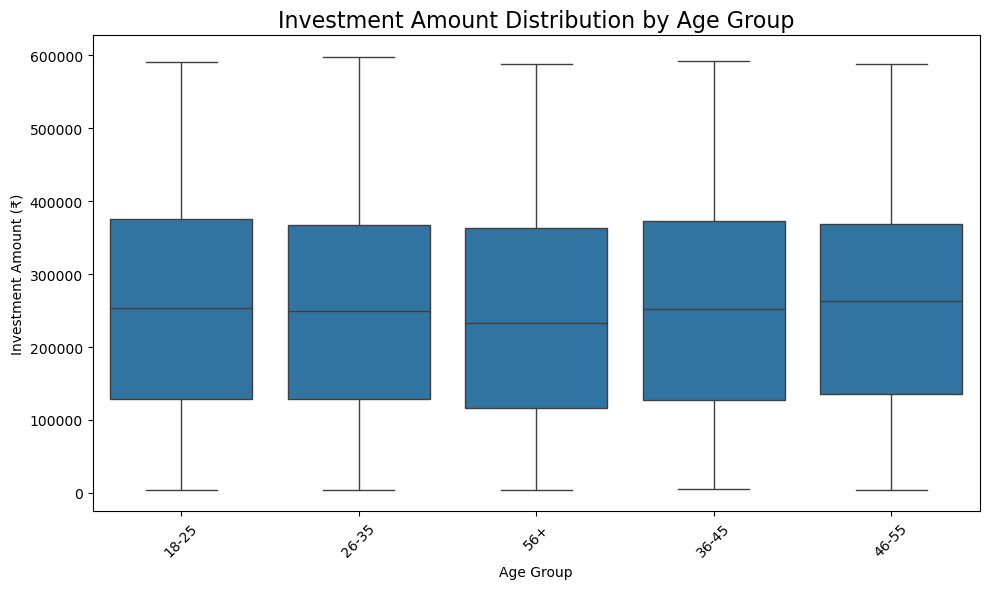

In [47]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=transactions,
    x="age_group",
    y="amount_inr"
)

plt.title("Investment Amount Distribution by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Investment Amount (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

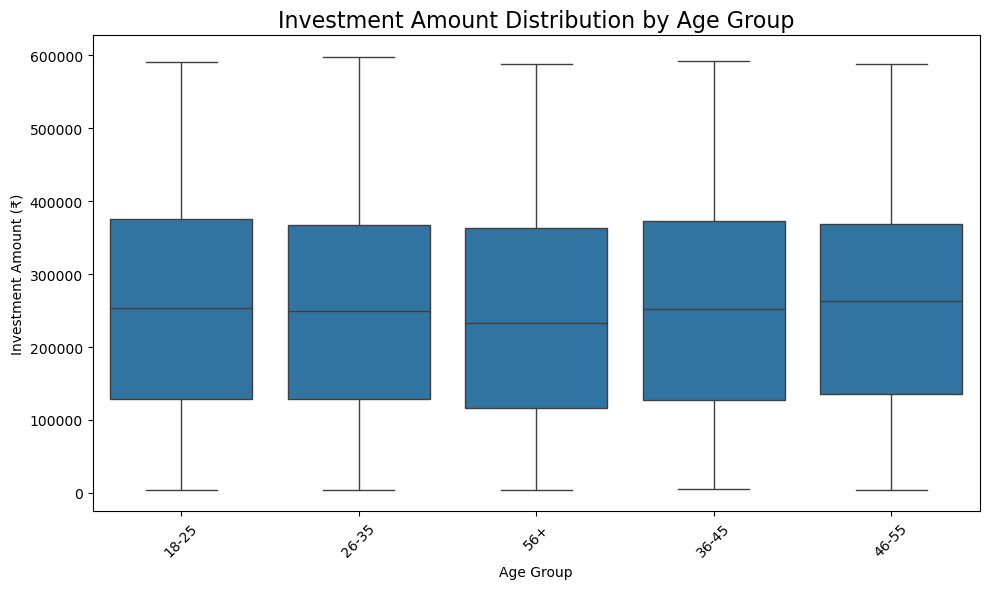

Age-wise Investment Box Plot Saved Successfully!


In [48]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=transactions,
    x="age_group",
    y="amount_inr"
)

plt.title("Investment Amount Distribution by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Investment Amount (₹)")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "charts/investment_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Age-wise Investment Box Plot Saved Successfully!")

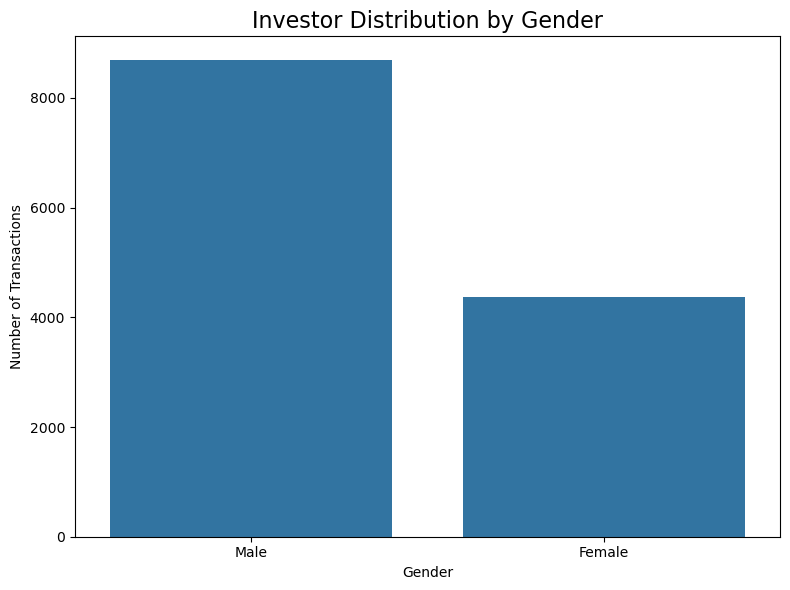

In [49]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=transactions,
    x="gender"
)

plt.title("Investor Distribution by Gender", fontsize=16)
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

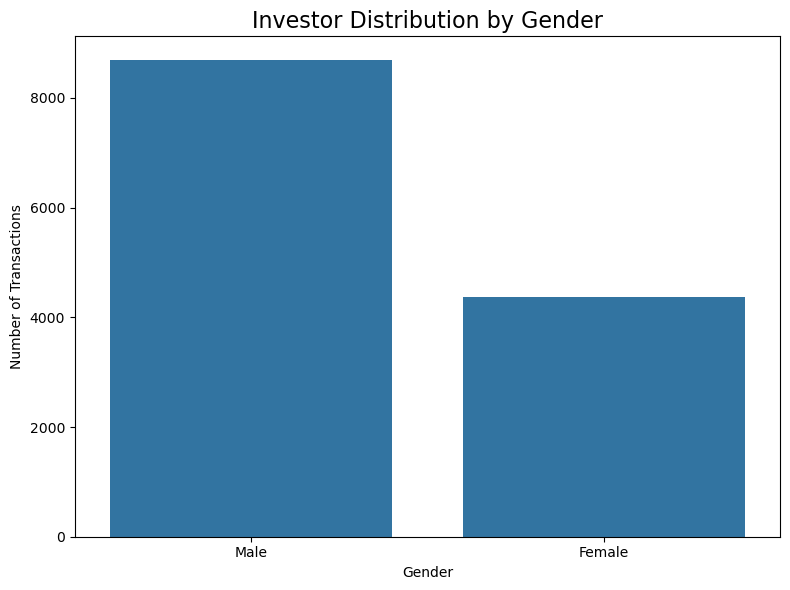

Gender Distribution Chart Saved Successfully!


In [50]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=transactions,
    x="gender"
)

plt.title("Investor Distribution by Gender", fontsize=16)
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(
    "charts/investor_gender_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gender Distribution Chart Saved Successfully!")

In [51]:
state_investment = transactions.groupby("state")["amount_inr"].sum().sort_values(ascending=False)

print("Top 15 States by Investment Amount:")
print(state_investment.head(15))

Top 15 States by Investment Amount:
state
Tamil Nadu        296772869
Punjab            295640395
Madhya Pradesh    287630250
Rajasthan         282101589
Gujarat           279980036
West Bengal       279686745
Delhi             272519796
Telangana         271599068
Uttar Pradesh     267834015
Haryana           261457658
Karnataka         256056667
Maharashtra       253067851
Name: amount_inr, dtype: int64


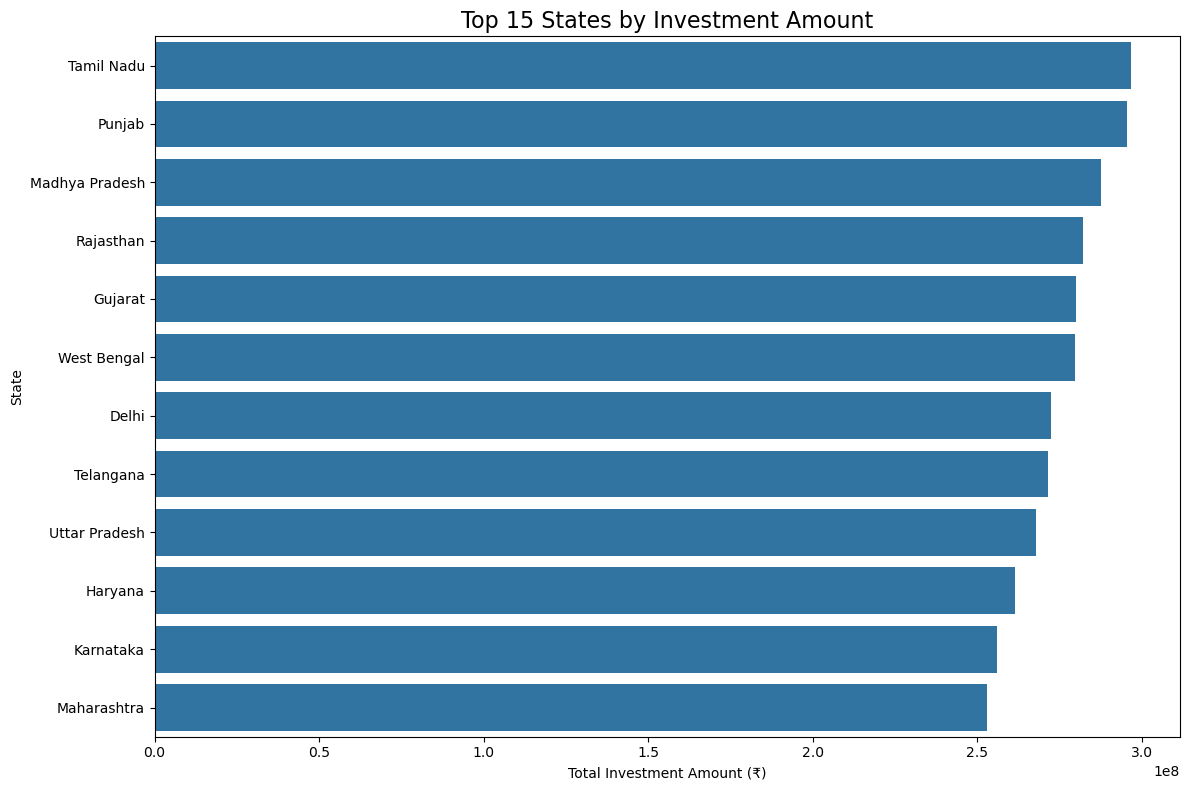

In [52]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=state_investment.head(15).values,
    y=state_investment.head(15).index
)

plt.title("Top 15 States by Investment Amount", fontsize=16)
plt.xlabel("Total Investment Amount (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

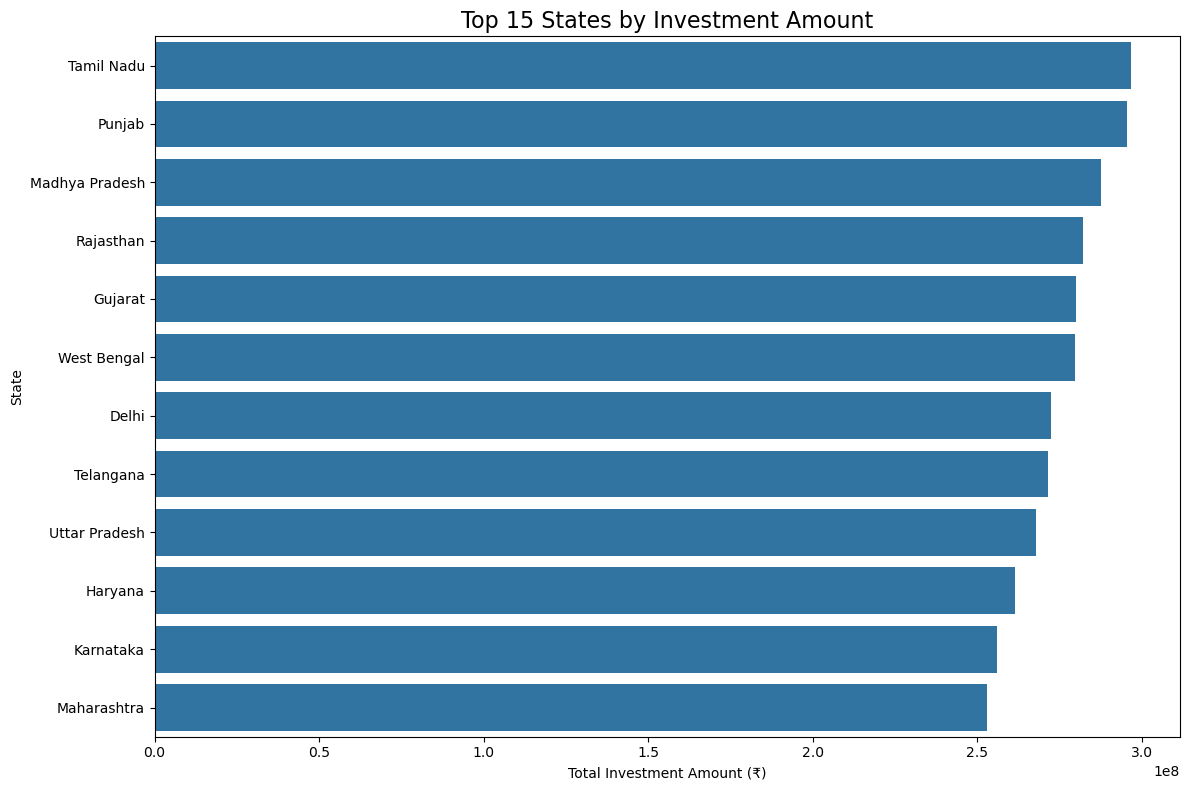

State-wise Investment Chart Saved Successfully!


In [53]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=state_investment.head(15).values,
    y=state_investment.head(15).index
)

plt.title("Top 15 States by Investment Amount", fontsize=16)
plt.xlabel("Total Investment Amount (₹)")
plt.ylabel("State")

plt.tight_layout()

plt.savefig(
    "charts/state_wise_investment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("State-wise Investment Chart Saved Successfully!")

In [54]:
print("City Tier Distribution:")
print(transactions["city_tier"].value_counts())

print("\nUnique City Tiers:")
print(transactions["city_tier"].unique())

City Tier Distribution:
city_tier
T30    8596
B30    4466
Name: count, dtype: int64

Unique City Tiers:
['B30' 'T30']


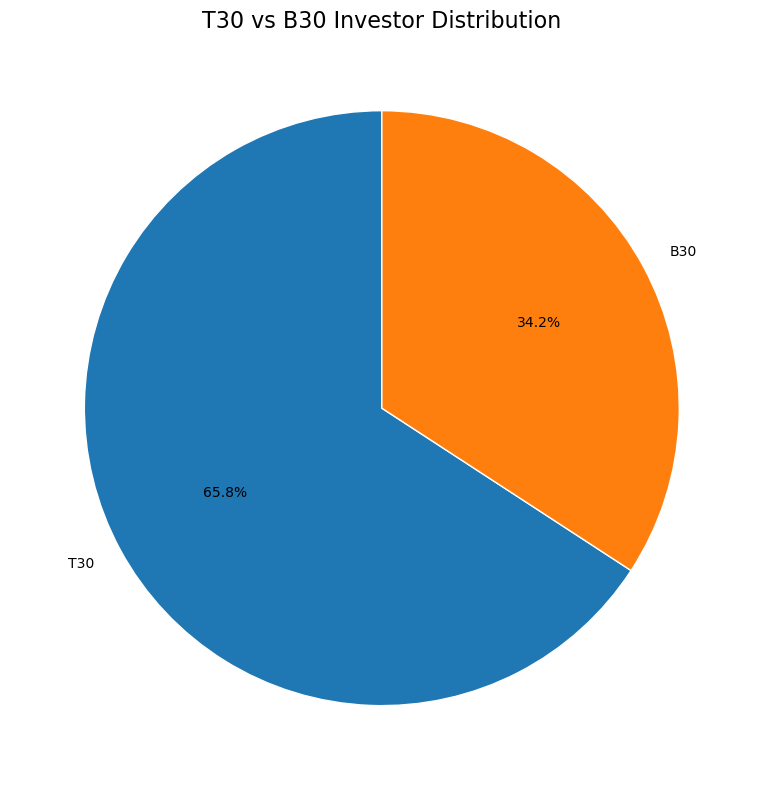

In [55]:
city_tier_counts = transactions["city_tier"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    city_tier_counts,
    labels=city_tier_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("T30 vs B30 Investor Distribution", fontsize=16)
plt.tight_layout()

plt.show()

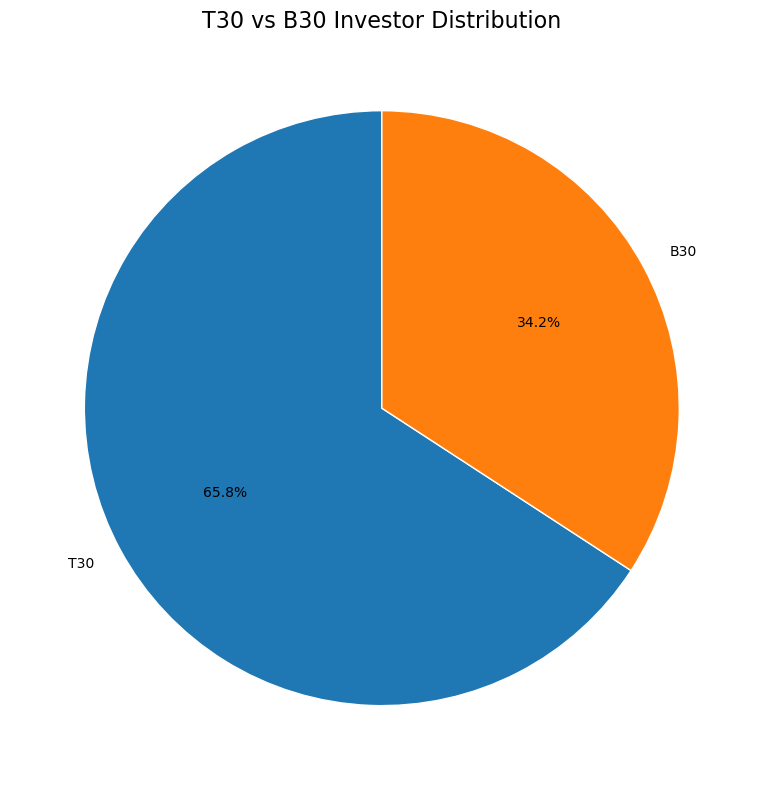

T30 vs B30 Chart Saved Successfully!


In [56]:
plt.figure(figsize=(8, 8))

plt.pie(
    city_tier_counts,
    labels=city_tier_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("T30 vs B30 Investor Distribution", fontsize=16)
plt.tight_layout()

plt.savefig(
    "charts/t30_vs_b30_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("T30 vs B30 Chart Saved Successfully!")

In [57]:
folio = pd.read_csv(
    "data/processed/industry_folio_count_cleaned.csv"
)

folio["month"] = pd.to_datetime(folio["month"])

folio = folio.sort_values("month")

print("Folio Dataset Shape:", folio.shape)

print("\nFolio Dataset:")
print(folio.head())

print("\nFolio Columns:")
print(folio.columns.tolist())

Folio Dataset Shape: (21, 6)

Folio Dataset:
       month  total_folios_crore  equity_folios_crore  debt_folios_crore  \
0 2022-01-01               13.26                 9.28               1.86   
1 2022-04-01               13.91                 9.74               1.95   
2 2022-07-01               13.85                 9.69               1.94   
3 2022-10-01               14.12                 9.88               1.98   
4 2023-01-01               14.81                10.37               2.07   

   hybrid_folios_crore  others_folios_crore  
0                 0.80                 1.33  
1                 0.83                 1.39  
2                 0.83                 1.38  
3                 0.85                 1.41  
4                 0.89                 1.48  

Folio Columns:
['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']


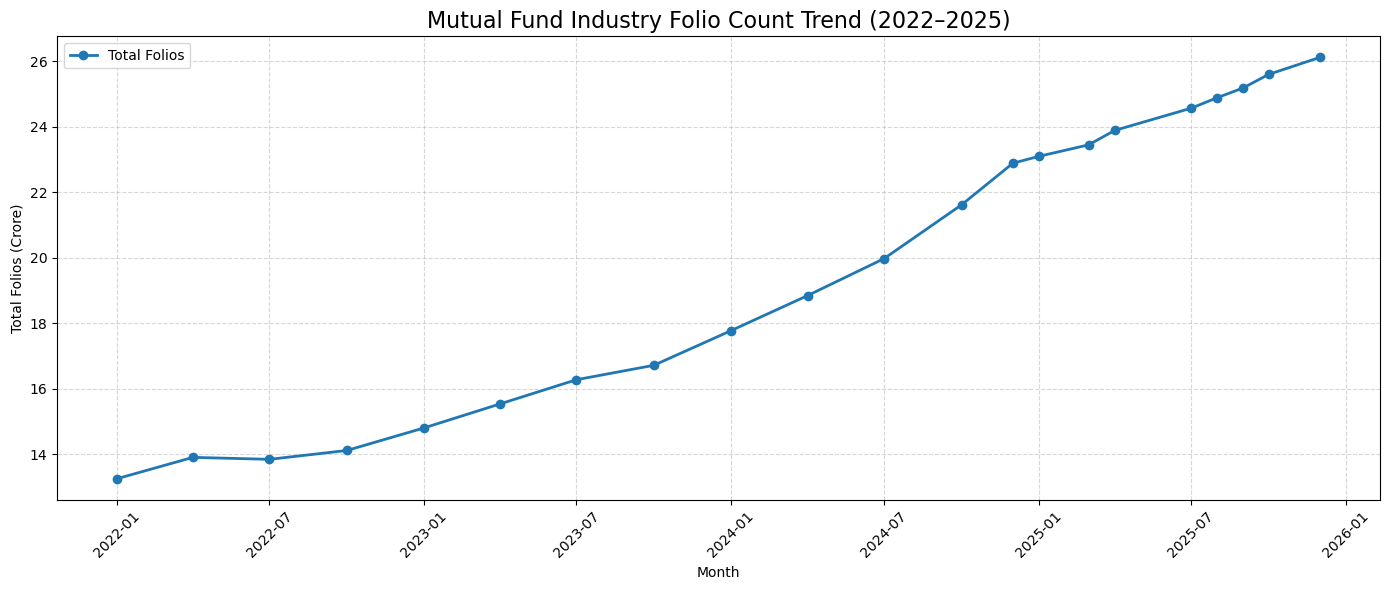

In [58]:
plt.figure(figsize=(14, 6))

plt.plot(
    folio["month"],
    folio["total_folios_crore"],
    marker="o",
    linewidth=2,
    label="Total Folios"
)

plt.title("Mutual Fund Industry Folio Count Trend (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

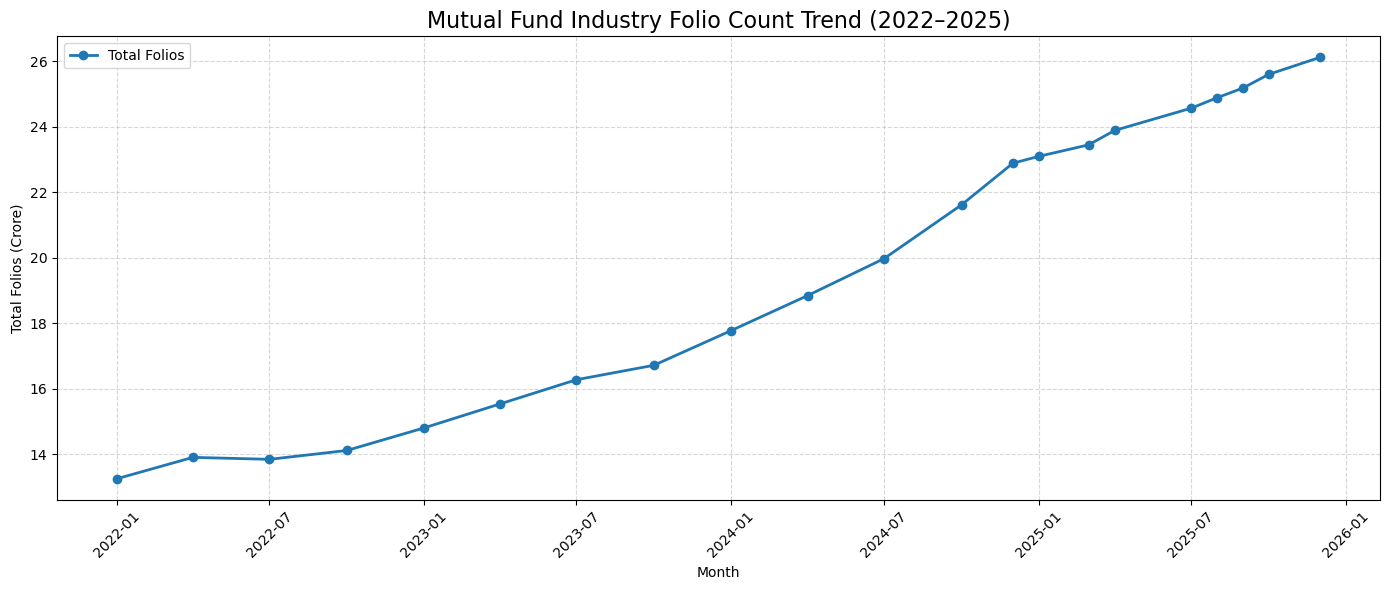

Folio Count Chart Saved Successfully!


In [59]:
plt.figure(figsize=(14, 6))

plt.plot(
    folio["month"],
    folio["total_folios_crore"],
    marker="o",
    linewidth=2,
    label="Total Folios"
)

plt.title("Mutual Fund Industry Folio Count Trend (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "charts/folio_count_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Folio Count Chart Saved Successfully!")

In [60]:
nav = pd.read_csv(
    "data/processed/nav_history_cleaned.csv"
)

fund = pd.read_csv(
    "data/processed/fund_master_cleaned.csv"
)

nav["date"] = pd.to_datetime(nav["date"])

nav_merged = pd.merge(
    nav,
    fund[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

print("NAV Dataset Loaded Successfully!")
print("Unique Schemes:", nav_merged["scheme_name"].nunique())

print(nav_merged.head())

NAV Dataset Loaded Successfully!
Unique Schemes: 40
   amfi_code       date       nav                                scheme_name
0     100016 2022-01-03  520.4608  HDFC Top 100 Fund - Regular Plan - Growth
1     100016 2022-01-04  515.0971  HDFC Top 100 Fund - Regular Plan - Growth
2     100016 2022-01-05  521.7239  HDFC Top 100 Fund - Regular Plan - Growth
3     100016 2022-01-06  515.7880  HDFC Top 100 Fund - Regular Plan - Growth
4     100016 2022-01-07  515.1639  HDFC Top 100 Fund - Regular Plan - Growth


In [61]:
top_10_schemes = (
    nav_merged["scheme_name"]
    .dropna()
    .unique()[:10]
)

print("Selected 10 Mutual Fund Schemes:")
for scheme in top_10_schemes:
    print(scheme)

Selected 10 Mutual Fund Schemes:
HDFC Top 100 Fund - Regular Plan - Growth
HDFC Short Term Debt Fund - Regular - Growth
HDFC Mid-Cap Opportunities Fund - Regular - Growth
ABSL Frontline Equity Fund - Regular - Growth
ABSL Small Cap Fund - Regular - Growth
ABSL Liquid Fund - Regular - Growth
UTI Nifty 50 Index Fund - Regular - Growth
UTI Mid Cap Fund - Regular - Growth
UTI Flexi Cap Fund - Regular - Growth
Nippon India Large Cap Fund - Regular - Growth


In [62]:
nav_10 = nav_merged[
    nav_merged["scheme_name"].isin(top_10_schemes)
].copy()

nav_10 = nav_10.sort_values(["scheme_name", "date"])

nav_10["daily_return"] = (
    nav_10.groupby("scheme_name")["nav"]
    .pct_change() * 100
)

returns_pivot = nav_10.pivot(
    index="date",
    columns="scheme_name",
    values="daily_return"
)

print("Daily Returns Calculated Successfully!")
print("Returns Shape:", returns_pivot.shape)

display(returns_pivot.head())

Daily Returns Calculated Successfully!
Returns Shape: (1150, 10)


scheme_name,ABSL Frontline Equity Fund - Regular - Growth,ABSL Liquid Fund - Regular - Growth,ABSL Small Cap Fund - Regular - Growth,HDFC Mid-Cap Opportunities Fund - Regular - Growth,HDFC Short Term Debt Fund - Regular - Growth,HDFC Top 100 Fund - Regular Plan - Growth,Nippon India Large Cap Fund - Regular - Growth,UTI Flexi Cap Fund - Regular - Growth,UTI Mid Cap Fund - Regular - Growth,UTI Nifty 50 Index Fund - Regular - Growth
date,,,,,,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-04,0.115307,-0.014095,-1.086494,-1.332796,-0.355285,-1.030568,-0.071439,-1.045888,1.131440,1.112239
2022-01-05,0.386641,0.038237,0.060281,-0.438625,-0.004957,1.286515,0.591310,-0.530798,0.677883,-0.787808
2022-01-06,-0.212763,-0.014349,-2.910091,-0.516686,-0.188009,-1.137747,0.353954,1.267825,3.112681,1.527677
2022-01-07,-0.631414,0.021527,2.476630,-0.574832,0.203647,-0.120999,-0.579280,-1.649790,-0.883514,-0.936922


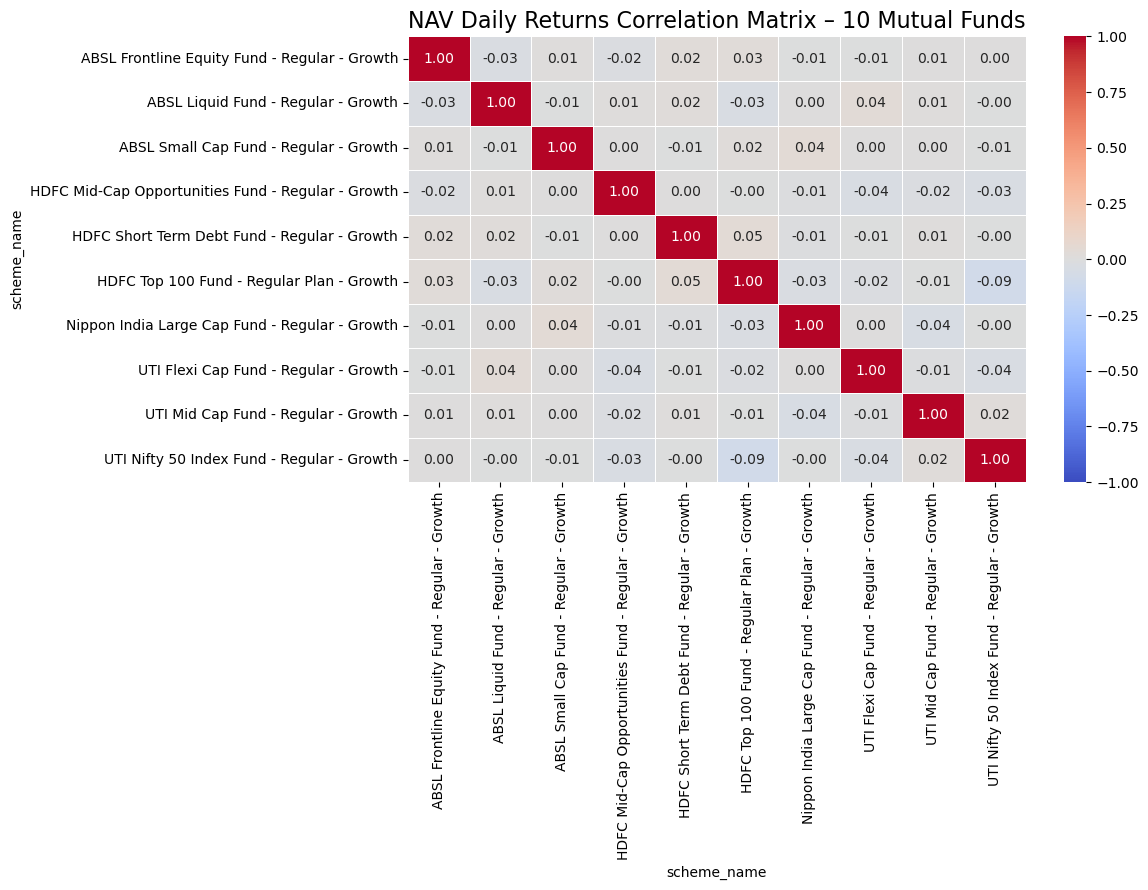

In [63]:
correlation_matrix = returns_pivot.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("NAV Daily Returns Correlation Matrix – 10 Mutual Funds", fontsize=16)
plt.tight_layout()

plt.show()

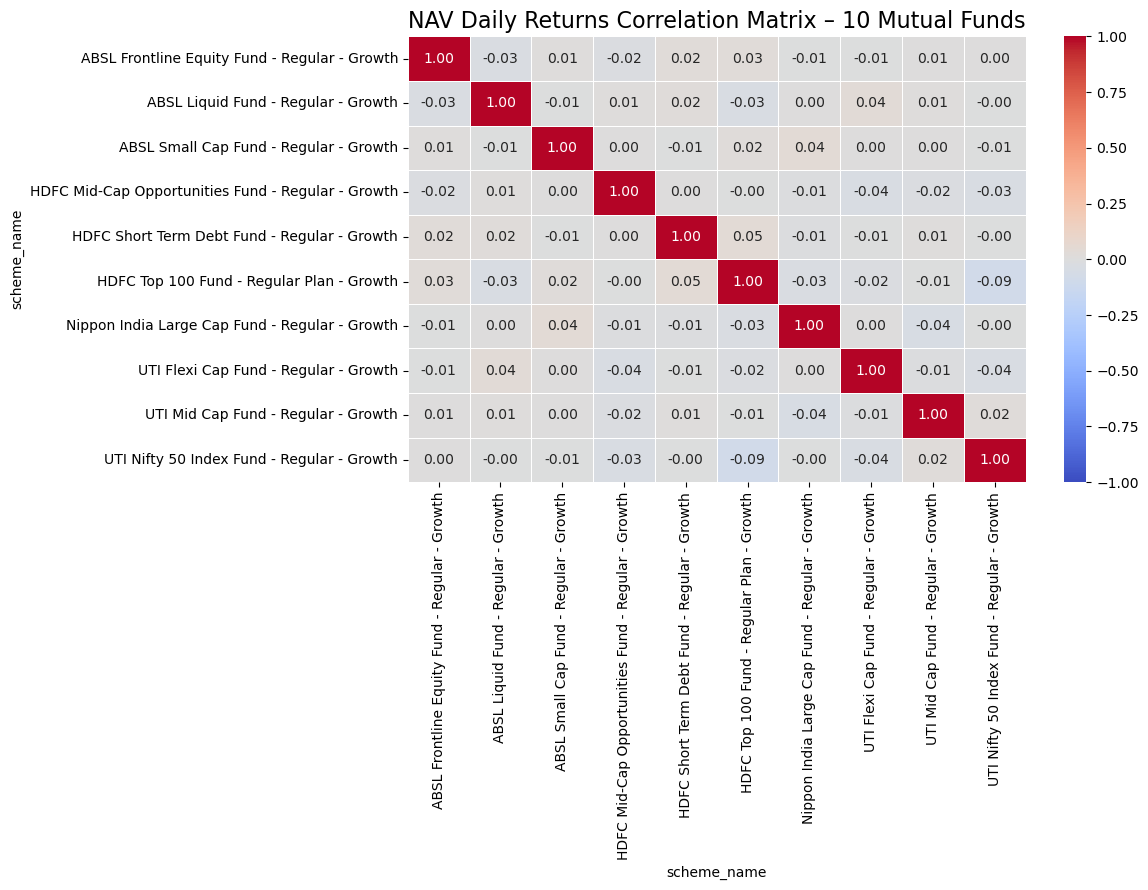

NAV Correlation Heatmap Saved Successfully!


In [64]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("NAV Daily Returns Correlation Matrix – 10 Mutual Funds", fontsize=16)
plt.tight_layout()

plt.savefig(
    "charts/nav_return_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("NAV Correlation Heatmap Saved Successfully!")

In [65]:
holdings = pd.read_csv(
    "data/processed/portfolio_holdings_cleaned.csv"
)

print("Holdings Dataset Shape:", holdings.shape)

print("\nAvailable Columns:")
print(holdings.columns.tolist())

print("\nAvailable Sectors:")
print(holdings["sector"].unique())

print("\nFirst 10 Records:")
print(holdings.head(10))

Holdings Dataset Shape: (322, 8)

Available Columns:
['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']

Available Sectors:
['Utilities' 'Banking' 'Diversified' 'Pharma' 'Paints' 'Telecom' 'IT'
 'Automobile' 'NBFC' 'Cement' 'Energy' 'Consumer Goods' 'FMCG'
 'Infrastructure']

First 10 Records:
   amfi_code stock_symbol                stock_name       sector  weight_pct  \
0     119551    POWERGRID    Power Grid Corporation    Utilities       13.85   
1     119551     HDFCBANK             HDFC Bank Ltd      Banking       11.19   
2     119551       GRASIM     Grasim Industries Ltd  Diversified        9.90   
3     119551      DRREDDY  Dr. Reddy's Laboratories       Pharma        4.76   
4     119551   ASIANPAINT          Asian Paints Ltd       Paints       10.25   
5     119551         NTPC                  NTPC Ltd    Utilities        7.48   
6     119551     DIVISLAB       Divi's Laboratories       Pharma      

In [66]:
sector_allocation = (
    holdings.groupby("sector")["weight_pct"]
    .sum()
    .sort_values(ascending=False)
)

print("Sector-wise Portfolio Allocation:")
print(sector_allocation)

print("\nTotal Weight:", sector_allocation.sum())

Sector-wise Portfolio Allocation:
sector
Banking           652.26
IT                455.47
Pharma            407.45
Automobile        323.65
Utilities         265.54
FMCG              229.11
Infrastructure    192.16
Diversified       169.23
Telecom           145.62
Consumer Goods    127.61
NBFC              119.09
Energy            117.91
Cement            105.03
Paints             89.86
Name: weight_pct, dtype: float64

Total Weight: 3399.9900000000002


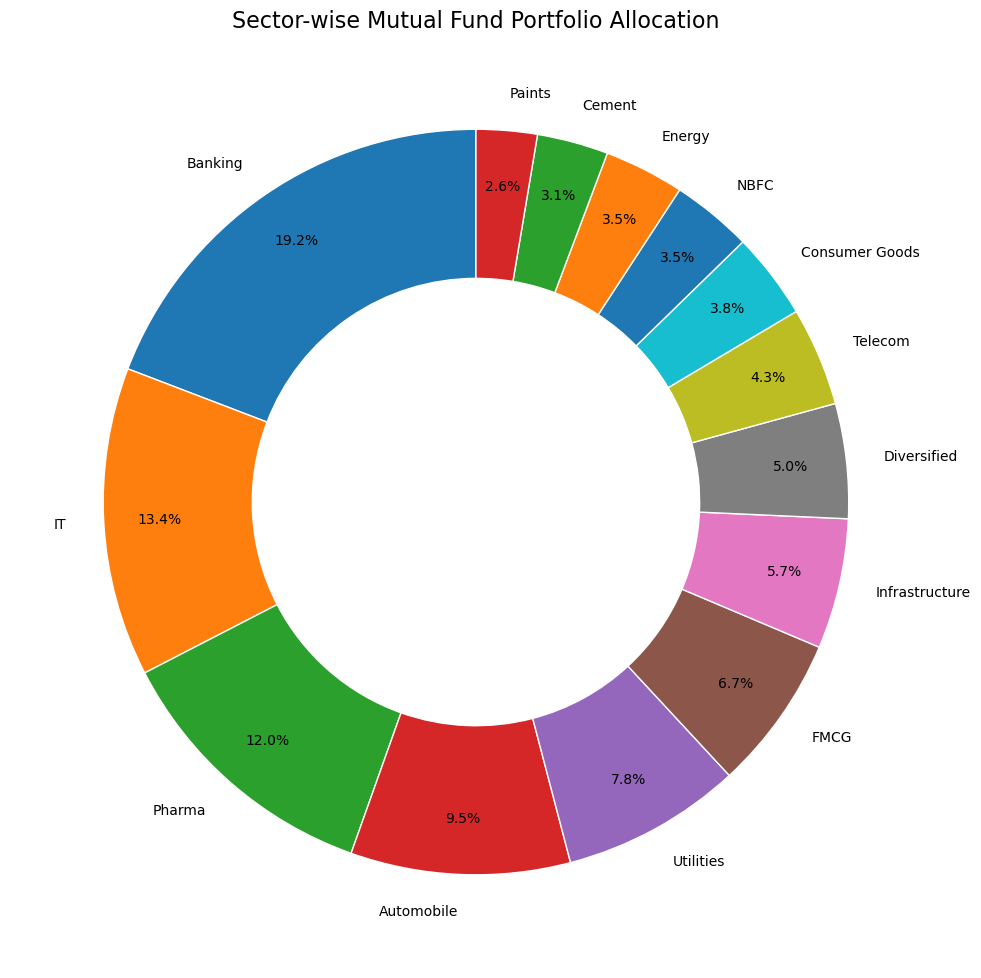

In [67]:
plt.figure(figsize=(10, 10))

plt.pie(
    sector_allocation,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.85,
    wedgeprops={
        "width": 0.4,
        "edgecolor": "white"
    }
)

plt.title("Sector-wise Mutual Fund Portfolio Allocation", fontsize=16)
plt.tight_layout()

plt.show()

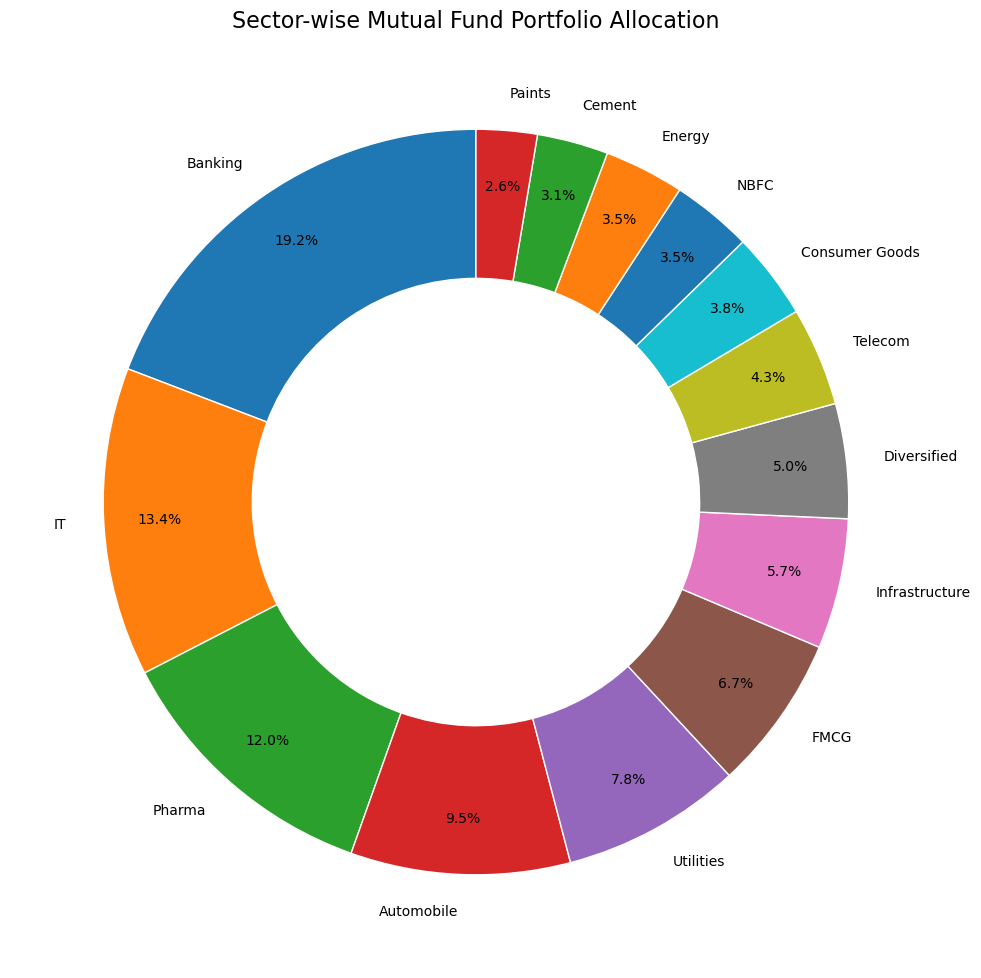

Sector Allocation Donut Chart Saved Successfully!


In [68]:
plt.figure(figsize=(10, 10))

plt.pie(
    sector_allocation,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.85,
    wedgeprops={
        "width": 0.4,
        "edgecolor": "white"
    }
)

plt.title("Sector-wise Mutual Fund Portfolio Allocation", fontsize=16)
plt.tight_layout()

plt.savefig(
    "charts/sector_portfolio_allocation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sector Allocation Donut Chart Saved Successfully!")

In [69]:
print("Fund Category Distribution:")
print(fund["category"].value_counts())

print("\nSub-Category Distribution:")
print(fund["sub_category"].value_counts())

Fund Category Distribution:
category
Equity    34
Debt       6
Name: count, dtype: int64

Sub-Category Distribution:
sub_category
Large Cap          14
Mid Cap             7
Small Cap           6
Liquid              3
Gilt                2
Flexi Cap           2
Short Duration      1
Value               1
Index/ETF           1
Index               1
Large & Mid Cap     1
ELSS                1
Name: count, dtype: int64


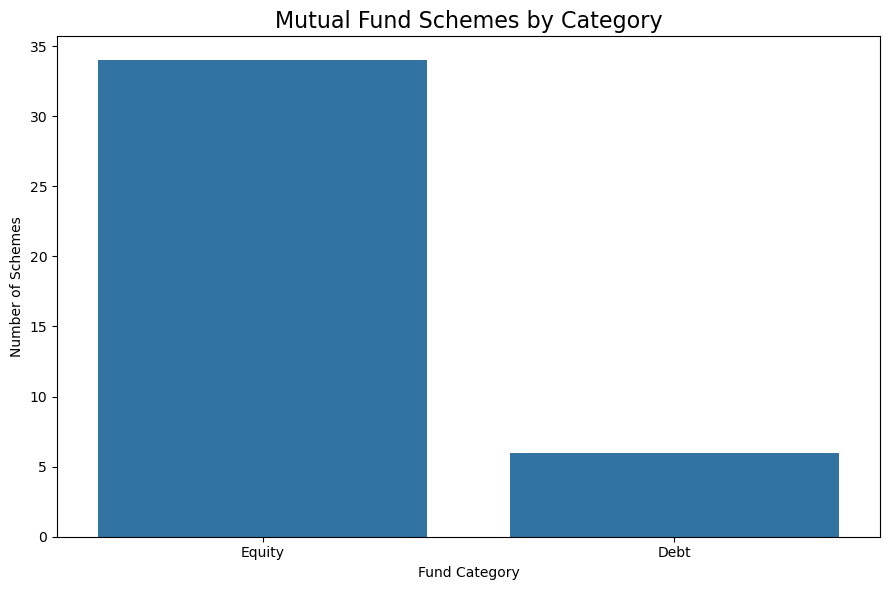

In [70]:
category_counts = fund["category"].value_counts()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Mutual Fund Schemes by Category", fontsize=16)
plt.xlabel("Fund Category")
plt.ylabel("Number of Schemes")

plt.tight_layout()
plt.show()

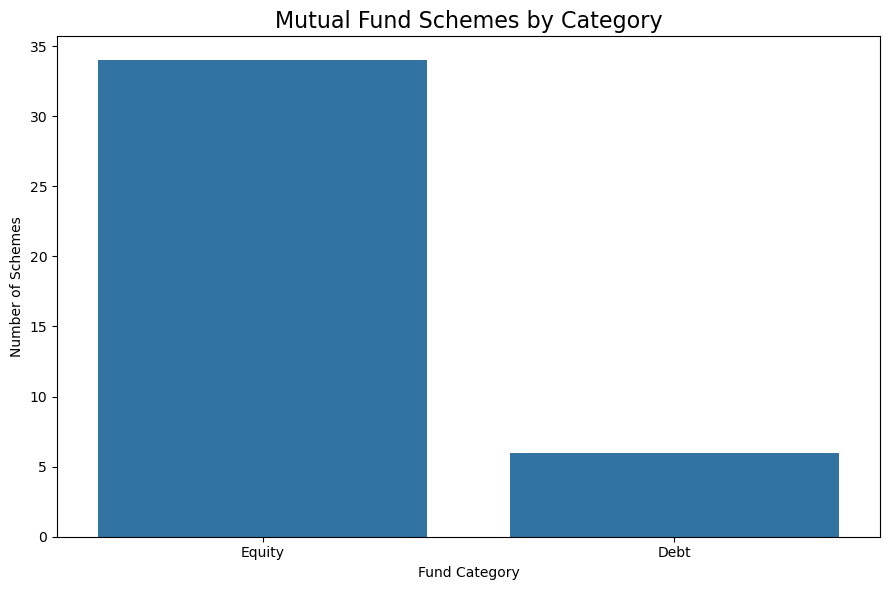

Fund Category Chart Saved Successfully!


In [71]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Mutual Fund Schemes by Category", fontsize=16)
plt.xlabel("Fund Category")
plt.ylabel("Number of Schemes")

plt.tight_layout()

plt.savefig(
    "charts/fund_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fund Category Chart Saved Successfully!")

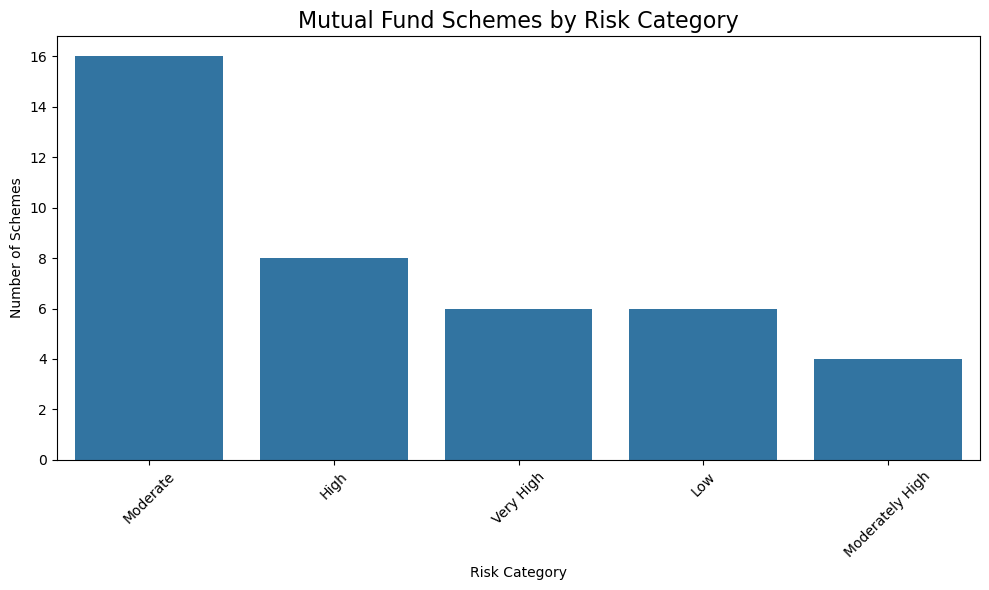

In [72]:
risk_counts = fund["risk_category"].value_counts()

plt.figure(figsize=(10, 6))

sns.countplot(
    data=fund,
    x="risk_category",
    order=risk_counts.index
)

plt.title("Mutual Fund Schemes by Risk Category", fontsize=16)
plt.xlabel("Risk Category")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

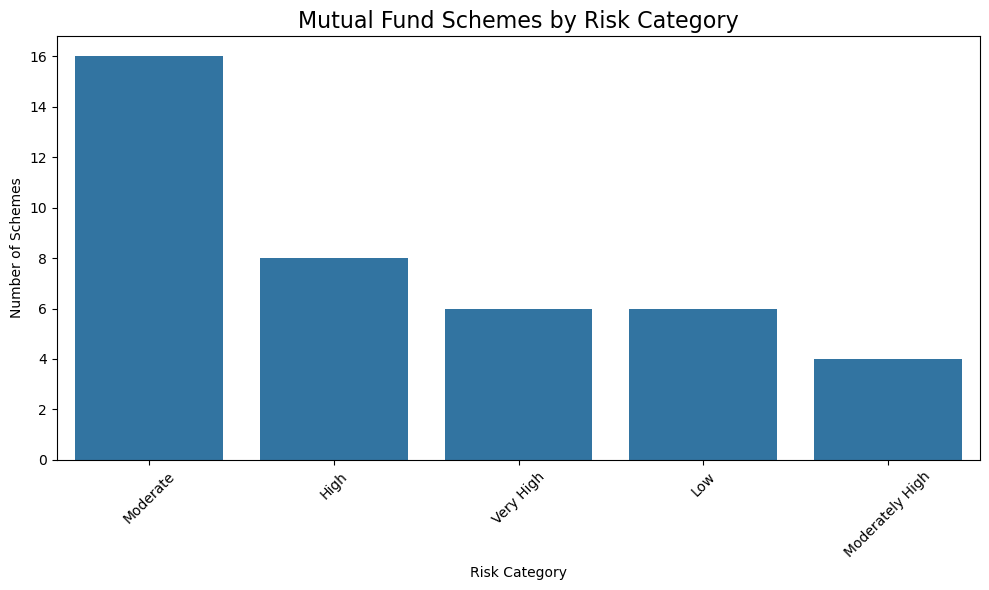

Risk Category Chart Saved Successfully!


In [73]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=fund,
    x="risk_category",
    order=risk_counts.index
)

plt.title("Mutual Fund Schemes by Risk Category", fontsize=16)
plt.xlabel("Risk Category")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "charts/risk_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Risk Category Chart Saved Successfully!")

In [74]:
import os
import glob

chart_files = glob.glob("charts/*.png")

print("Total Charts:", len(chart_files))

print("\nSaved Chart Files:")
for file in sorted(chart_files):
    print(os.path.basename(file))

Total Charts: 21

Saved Chart Files:
age_group_distribution.png
age_group_investment_boxplot.png
aum_growth.png
category_inflow_heatmap.png
category_wise_folio_growth.png
folio_count_growth.png
folio_count_trend.png
fund_category_distribution.png
gender_distribution.png
investment_by_age_group.png
investor_age_distribution.png
investor_gender_distribution.png
nav_return_correlation.png
nav_trend.png
risk_category_distribution.png
sbi_aum_growth.png
sector_portfolio_allocation.png
sip_inflow.png
state_wise_investment.png
t30_b30_investment.png
t30_vs_b30_distribution.png


In [75]:
print("========== EDA SUMMARY ==========")

print("\n1. NAV:")
print("Total Schemes:", nav_merged["scheme_name"].nunique())
print("Date Range:", nav_merged["date"].min(), "to", nav_merged["date"].max())

print("\n2. AUM:")
print(aum.groupby("fund_house")["aum_lakh_crore"].max().sort_values(ascending=False).head(5))

print("\n3. SIP:")
print("Highest SIP Inflow:", sip["sip_inflow_crore"].max())
print("Highest SIP Month:", sip.loc[sip["sip_inflow_crore"].idxmax(), "month"])

print("\n4. Investor Age:")
print(transactions["age_group"].value_counts())

print("\n5. Gender:")
print(transactions["gender"].value_counts())

print("\n6. Top 5 States:")
print(state_investment.head(5))

print("\n7. Folio Growth:")
print("First:", folio["total_folios_crore"].iloc[0])
print("Last:", folio["total_folios_crore"].iloc[-1])

print("\n8. Top Sector:")
print(sector_allocation.head(5))

print("\n9. Fund Categories:")
print(fund["category"].value_counts())

print("\n10. Risk Categories:")
print(fund["risk_category"].value_counts())

========== EDA SUMMARY ==========

1. NAV:
Total Schemes: 40
Date Range: 2022-01-03 00:00:00 to 2026-05-29 00:00:00

2. AUM:


NameError: name 'aum' is not defined

In [76]:
aum = pd.read_csv(
    "data/processed/aum_by_fund_house_cleaned.csv"
)

aum["date"] = pd.to_datetime(aum["date"])

print("AUM Dataset Loaded Successfully!")
print(aum.head())

AUM Dataset Loaded Successfully!
        date                fund_house  aum_lakh_crore  aum_crore  num_schemes
0 2022-03-31  Aditya Birla Sun Life MF            2.78     278000          199
1 2022-09-30  Aditya Birla Sun Life MF            2.85     285000          199
2 2023-03-31  Aditya Birla Sun Life MF            2.75     275000          199
3 2023-09-30  Aditya Birla Sun Life MF            3.08     308000          199
4 2024-03-31  Aditya Birla Sun Life MF            3.40     340000          199


In [77]:
print("========== EDA SUMMARY ==========")

print("\n1. NAV:")
print("Total Schemes:", nav_merged["scheme_name"].nunique())
print("Date Range:", nav_merged["date"].min(), "to", nav_merged["date"].max())

print("\n2. AUM:")
print(aum.groupby("fund_house")["aum_lakh_crore"].max().sort_values(ascending=False).head(5))

print("\n3. SIP:")
print("Highest SIP Inflow:", sip["sip_inflow_crore"].max())
print("Highest SIP Month:", sip.loc[sip["sip_inflow_crore"].idxmax(), "month"])

print("\n4. Investor Age:")
print(transactions["age_group"].value_counts())

print("\n5. Gender:")
print(transactions["gender"].value_counts())

print("\n6. Top 5 States:")
print(state_investment.head(5))

print("\n7. Folio Growth:")
print("First:", folio["total_folios_crore"].iloc[0])
print("Last:", folio["total_folios_crore"].iloc[-1])

print("\n8. Top Sector:")
print(sector_allocation.head(5))

print("\n9. Fund Categories:")
print(fund["category"].value_counts())

print("\n10. Risk Categories:")
print(fund["risk_category"].value_counts())

========== EDA SUMMARY ==========

1. NAV:
Total Schemes: 40
Date Range: 2022-01-03 00:00:00 to 2026-05-29 00:00:00

2. AUM:
fund_house
SBI Mutual Fund        12.50
ICICI Prudential MF    10.74
HDFC Mutual Fund        9.30
Nippon India MF         7.00
Kotak Mahindra MF       5.80
Name: aum_lakh_crore, dtype: float64

3. SIP:
Highest SIP Inflow: 31002
Highest SIP Month: 2025-12-01 00:00:00

4. Investor Age:
age_group
26-35    5400
36-45    3220
18-25    1967
46-55    1479
56+       996
Name: count, dtype: int64

5. Gender:
gender
Male      8687
Female    4375
Name: count, dtype: int64

6. Top 5 States:
state
Tamil Nadu        296772869
Punjab            295640395
Madhya Pradesh    287630250
Rajasthan         282101589
Gujarat           279980036
Name: amount_inr, dtype: int64

7. Folio Growth:
First: 13.26
Last: 26.12

8. Top Sector:
sector
Banking       652.26
IT            455.47
Pharma        407.45
Automobile    323.65
Utilities     265.54
Name: weight_pct, dtype: float64

9. Fund C

In [78]:
print("1. Gender Distribution:")
print(transactions["gender"].value_counts())

print("\n2. Top 5 States:")
print(state_investment.head(5))

print("\n3. Folio Growth:")
print("First:", folio["total_folios_crore"].iloc[0])
print("Last:", folio["total_folios_crore"].iloc[-1])

print("\n4. Top 5 Sectors:")
print(sector_allocation.head(5))

print("\n5. Fund Categories:")
print(fund["category"].value_counts())

print("\n6. Risk Categories:")
print(fund["risk_category"].value_counts())

1. Gender Distribution:
gender
Male      8687
Female    4375
Name: count, dtype: int64

2. Top 5 States:
state
Tamil Nadu        296772869
Punjab            295640395
Madhya Pradesh    287630250
Rajasthan         282101589
Gujarat           279980036
Name: amount_inr, dtype: int64

3. Folio Growth:
First: 13.26
Last: 26.12

4. Top 5 Sectors:
sector
Banking       652.26
IT            455.47
Pharma        407.45
Automobile    323.65
Utilities     265.54
Name: weight_pct, dtype: float64

5. Fund Categories:
category
Equity    34
Debt       6
Name: count, dtype: int64

6. Risk Categories:
risk_category
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4
Name: count, dtype: int64


# 10 Key Exploratory Data Analysis (EDA) Findings

### 1. NAV Trend Analysis
The dataset contains 40 mutual fund schemes with NAV records from January 2022 to May 2026, providing a broad view of historical NAV movements.

**Chart Reference:** `nav_trend.png`

### 2. AUM Growth Analysis
SBI Mutual Fund recorded the highest AUM of ₹12.50 lakh crore in the dataset, followed by ICICI Prudential MF at ₹10.74 lakh crore.

**Chart Reference:** `aum_growth.png`, `sbi_aum_growth.png`

### 3. SIP Inflow Analysis
Monthly SIP inflows reached their highest recorded value of ₹31,002 crore in December 2025.

**Chart Reference:** `sip_inflow.png`

### 4. Investor Age Distribution
Investors in the 26–35 age group recorded the highest transaction count, with 5,400 transactions.

**Chart Reference:** `investor_age_distribution.png`

### 5. Gender-wise Investor Analysis
Male transactions accounted for 8,687 records, while female transactions accounted for 4,375 records in the dataset.

**Chart Reference:** `investor_gender_distribution.png`

### 6. Geographic Investment Analysis
Tamil Nadu recorded the highest total transaction amount among the listed states, with ₹296,772,869, followed by Punjab.

**Chart Reference:** `state_wise_investment.png`

### 7. Mutual Fund Folio Growth
Total mutual fund folios increased from 13.26 crore to 26.12 crore during the observed period, showing substantial growth in folio registrations.

**Chart Reference:** `folio_count_trend.png`

### 8. NAV Return Correlation Analysis
The correlation heatmap compares daily NAV returns across 10 selected mutual fund schemes and helps identify relationships between their return movements.

**Chart Reference:** `nav_return_correlation.png`

### 9. Sector-wise Portfolio Allocation
Banking recorded the highest aggregated sector weight (652.26), followed by IT (455.47) and Pharma (407.45) in the holdings dataset.

**Chart Reference:** `sector_portfolio_allocation.png`

### 10. Fund Category and Risk Analysis
The fund master dataset provides scheme-level category and risk classifications. The category and risk distribution charts help compare the composition of the selected mutual fund schemes.

**Chart References:** `fund_category_distribution.png`, `risk_category_distribution.png`

import os
import glob

chart_files = glob.glob("charts/*.png")

print("========== FINAL EDA REPORT ==========")

print("Total Charts:", len(chart_files))

print("\nCharts Folder:")
for file in sorted(chart_files):
    print("✔", os.path.basename(file))

print("\nEDA Findings: 10")
print("Notebook: EDA_Analysis.ipynb")

print("\nEDA Analysis Verification Completed!")